# Retrouver les règles du Nutri-Score — Partie 1

### Préparation des données et calculateur Nutri-Score de référence

| | |
|---|---|
| Cours | Data Mining — EMSI, 5IIRK-DDSI G1 |
| Enseignante | Pr. Hiba El Balbali |
| Partie 1 (ce notebook) | **Taha Ait Baissi** |
| Partie 2 (suite) | **Yassine Amjad** — arbre de décision, évaluation, analyse des exceptions |
| Données | [Open Food Facts](https://world.openfoodfacts.org/data) — licence **ODbL**, © Open Food Facts contributors |
| Fichier brut | `data/raw/food.parquet` (export Parquet du dataset Hugging Face `openfoodfacts/product-database`) |
| Snapshot du fichier | 17/11/2026 |

> **Périmètre.** Ce notebook couvre les étapes KDD **1 à 3** (sélection, prétraitement, transformation),
> la **séparation train / validation / test** et le **calculateur Nutri-Score de référence**.
> L'étape KDD 4 (*Data Mining* : arbre de décision) et l'étape 5 (*Évaluation & Interprétation*)
> sont la partie de Yassine. Le contrat de données est dans `HANDOFF.md`.

**Reproductibilité** : noyau Python, `RANDOM_STATE = 42`, notebook exécuté de bout en bout, sorties conservées.

## 0. Compréhension du problème *(hors KDD)*

**Question posée (énoncé, verbatim)** : « *Sur une catégorie Open Food Facts, entraîner un arbre de décision
à retrouver le Nutri-Score à partir des nutriments et analyser les produits qui font exception.* »

**Où se situe le projet dans la chaîne Données → Information → Connaissance → Décision ?**

- **Données** : des millions de fiches produits brutes, incomplètes et hétérogènes (Open Food Facts).
- **Information** : un sous-ensemble propre d'une catégorie, avec 7 nutriments pour 100 g et la note officielle A–E.
- **Connaissance** : les règles que l'arbre va apprendre (seuils sur l'énergie, les sucres, le sel…) et les exceptions.
- **Décision** : disposer d'un modèle interprétable pour contrôler un étiquetage, détecter des erreurs et discuter
  la qualité nutritionnelle des produits.

**Un bon modèle est valide, nouveau, utile, compréhensible** (grille du cours) :

| Critère | Réponse pour un arbre qui retrouve le Nutri-Score |
|---|---|
| Valide | Il doit reproduire une règle officielle déterministe : on peut mesurer exactement son accord avec OFF (score et lettre). |
| Nouveau | La règle n'est pas donnée au modèle : il la **redécouvre** à partir des nutriments. |
| Utile | Il permet de repérer les produits mal étiquetés ou les cas où OFF et le calcul officiel divergent. |
| Compréhensible | Un arbre se lit en règles `si … alors …`, exactement le langage du Nutri-Score. |

**Vocabulaire du cours appliqué au projet :**

- **Objet** (*individu*) : un produit alimentaire identifié par son code-barres.
- **Attributs** : les nutriments pour 100 g (quantitatifs continus).
- **Jeu de données** : le sous-ensemble d'une catégorie Open Food Facts.
- **Variable cible** : `grade`, **qualitative ordinale** A < B < C < D < E. L'ordre compte (A est meilleur que B),
  mais les écarts entre lettres ne sont pas des distances : c'est pourquoi on utilise un encodage ordinal `y_int = 0…4`
  et non un one-hot pour l'évaluation principale.

| Variable | Type | Rôle |
|---|---|---|
| `code` | qualitatif nominal (identifiant) | identifiant — **jamais** un attribut |
| `product_name` | qualitatif nominal | lisibilité / analyse des exceptions |
| `energy_kj` | quantitatif continu (kJ/100 g) | attribut d'analyse |
| `sat_fat` | quantitatif continu (g/100 g) | attribut d'analyse |
| `sugars` | quantitatif continu (g/100 g) | attribut d'analyse |
| `salt` | quantitatif continu (g/100 g) | attribut d'analyse |
| `fibre` | quantitatif continu (g/100 g) | attribut d'analyse |
| `proteins` | quantitatif continu (g/100 g) | attribut d'analyse |
| `fvl_pct` | quantitatif continu borné [0 ; 100] (%) | attribut d'analyse |
| `grade` | **qualitative ordinale** A < B < C < D < E | **variable cible** |
| `off_score` | quantitatif discret (entier) | métadonnée de contrôle — **interdit comme attribut** (fuite) |
| `score_v2021`, `score_v2023`, `grade_v2021`, `grade_v2023` | calculés | contrôle / analyse des exceptions — **interdits comme attributs** |
| `countries`, `last_modified`, `suspect_consistency` | métadonnées | analyse des exceptions uniquement |

**Hypothèse explicite.** Si l'arbre est précis, il doit **redécouvrir les seuils de l'algorithme officiel**
(par exemple « saturés > 10 g ⇒ 10 points »). Les produits qui font exception (mal classés, ou mal notés par OFF)
sont la partie la plus intéressante : c'est l'objet de la partie 2.

**Feuille de route KDD du notebook** (vocabulaire du cours) :

| Section | Étape KDD | Contenu |
|---|---|---|
| 1 | Sélection des données | schéma réel, choix de la catégorie, extraction, représentativité |
| 2 | Prétraitement / Nettoyage | diagnostic 5 contrôles, 6 dimensions qualité, valeurs aberrantes, valeurs manquantes, règles R1–R8 |
| 3 | Transformation | 7 attributs, unités, pas de normalisation, distribution des classes |
| 4 | Séparation | train / validation / test stratifiés 70/15/15, **avant toute statistique apprise** |
| 5 | Calculateur de référence | implémentation 2021 et 2023, tests unitaires, accord avec OFF, validation manuelle |
| 6 | Contrat & export | fichiers Parquet, assertions, passation à Yassine |

Les étapes KDD **4 (Data Mining)** et **5 (Évaluation & Interprétation)** appartiennent à la partie 2.

In [1]:
import hashlib
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Chemins RELATIFS au notebook (voir spec, section 1)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = (ROOT / "food.parquet") if (ROOT / "food.parquet").exists() else (ROOT / "data" / "raw" / "category_breakfast_cereals.parquet")
SUBSET = ROOT / "data" / "raw" / "category_breakfast_cereals.parquet"
PROCESSED = ROOT / "data" / "processed"
CONFIG = ROOT / "config" / "thresholds.yaml"
assert RAW.exists(), f"Dataset not found at {RAW}. See spec section 2."
PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT))
from src.nutriscore import FEATURES as _FEATURES, compute, grade, load_thresholds
FEATURES = list(_FEATURES)  # pandas 3 : une tuple est interprétée comme une seule clé

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

GRADES = ["A", "B", "C", "D", "E"]
print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__, "| duckdb", duckdb.__version__)
print("Chemins résolus depuis le dossier :", ROOT.name)

Python 3.12.16
pandas 3.1.1 | numpy 2.5.5 | duckdb 2.0.0
Chemins résolus depuis le dossier : PROJET


## 1. Sélection des données *(KDD étape 1)*

**Ce que l'on fait.** On part du Parquet complet d'Open Food Facts. On inspecte le schéma réel (jamais deviné),
on compte les produits par catégorie, puis on choisit **une** catégorie et on extrait uniquement les colonnes utiles.

**Pourquoi.** La sélection réduit le volume et le bruit, et fixe le périmètre de l'étude. Le cours insiste :
un attribut mal choisi ou une catégorie mal définie rend tout le reste faux.

**Notion du cours.** *Sélection des données* (KDD étape 1) et *échantillonnage* : population, échantillon,
biais de sélection et de couverture.

**Source et licence.** Open Food Facts, base collaborative sous licence **ODbL**.
Attribution obligatoire : « © Open Food Facts contributors — ODbL ». Les données sont déclaratives :
elles peuvent contenir des erreurs de saisie, des valeurs manquantes et des versions d'algorithme différentes.

In [2]:
con = duckdb.connect()
P = RAW.as_posix()
schema = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{P}')").df()
print(f"{len(schema)} colonnes dans le fichier brut\n")
print(schema[["column_name", "column_type"]].to_string(index=False))

111 colonnes dans le fichier brut

                           column_name                                                                                                                                                                                                                                             column_type
                           additives_n                                                                                                                                                                                                                                                 INTEGER
                        additives_tags                                                                                                                                                                                                                                               VARCHAR[]
                        allergens_tags                                                                  

**Ce que le schéma réel montre (et qui diffère des habitudes CSV) :**

- `nutriments` est une **liste de structures** `{name, value, 100g, serving, unit, …}` : un nutriment n'est pas
  une colonne, il faut faire un `UNNEST` puis un pivot conditionnel.
- `product_name` et `ingredients_text` sont des **listes de `{lang, text}`** (une entrée par langue).
- `categories_tags`, `countries_tags`, `brands_tags` sont des **listes** (`VARCHAR[]`).
- Il n'existe **aucune colonne** `nutriscore_version` : la version utilisée par OFF devra être **déduite**
  du couple (`nutriscore_score`, `nutriscore_grade`) — c'est fait en section 5.
- `last_modified_t` est un **timestamp Unix** (secondes), pas une date.

Ces constats sont vérifiés sur les données ci-dessous, pas supposés.

In [3]:
# Vue d'un produit : structure réelle du champ imbriqué `nutriments`
sample = con.sql(f'''
    SELECT code, product_name, nutriments
    FROM read_parquet(\'{P}\')
    WHERE nutriscore_grade IN (\'a\', \'e\')
    LIMIT 2
''').df()
for _, row in sample.iterrows():
    print("code :", row["code"], "| noms :", [x["text"] for x in row["product_name"]])
    print("  nutriments :", [(x["name"], x["100g"], x["unit"]) for x in row["nutriments"]][:10], "...\n")

# Volumétrie globale et distribution des grades
raw_counts = con.sql(f'''
    SELECT count(*) AS n_produits,
           count(*) FILTER (WHERE nutriscore_grade IN (\'a\',\'b\',\'c\',\'d\',\'e\')) AS n_grade_valide,
           count(*) FILTER (WHERE nutriscore_grade = \'unknown\')      AS n_unknown,
           count(*) FILTER (WHERE nutriscore_grade = \'not-applicable\') AS n_not_applicable,
           count(*) FILTER (WHERE nutriscore_grade IS NULL)           AS n_null
    FROM read_parquet(\'{P}\')
''').df()
display(raw_counts.T.rename(columns={0: "valeur"}))

code : 0000101209159 | noms : ['Véritable pâte à tartiner noisettes chocolat noir', 'Véritable pâte à tartiner noisettes chocolat noir']
  nutriments : [('sugars', 32.0, 'g'), ('energy-kj', 2524.0, 'kJ'), ('cocoa', 17.520000457763672, '%'), ('carbohydrates', 36.0, 'g'), ('sodium', 0.004000000189989805, 'g'), ('saturated-fat', 10.0, 'g'), ('fruits-vegetables-nuts', 70.30999755859375, '%'), ('salt', 0.009999999776482582, 'g'), ('fat', 48.0, 'g'), ('fruits-vegetables-legumes', 0.0, '%')] ...

code : 0000111301201 | noms : ['Canola Harvest® Original Vegetable Oil Spread Tub', 'Canola Harvest® Original Vegetable Oil Spread Tub', 'Original Buttery Spread']
  nutriments : [('fiber', 0.0, 'g'), ('fruits-vegetables-nuts-estimate-from-ingredients', 53.33333206176758, None), ('proteins', 0.0, 'g'), ('cholesterol', 0.0, 'mg'), ('sodium', 5.099999904632568, 'mg'), ('carbohydrates', 0.0, 'g'), ('saturated-fat', 76.4000015258789, 'g'), ('salt', 12.699999809265137, 'mg'), ('fat', 510.0, 'g'), ('sugars

,valeur
n_produits,4918257
n_grade_valide,1439492
n_unknown,3303398
n_not_applicable,109096
n_null,66271


In [4]:
# Comptage par catégorie candidate, restreint aux produits ayant un grade valide
candidates = [
    "en:breakfast-cereals", "en:biscuits", "en:chocolates", "en:yogurts",
    "en:breads", "en:sauces", "en:pizzas", "en:soups",
]
vals = ",".join(f"('{t}')" for t in candidates)
cat_counts = con.sql(f'''
    WITH cand(tag) AS (VALUES {vals})
    SELECT c.tag AS categorie,
           count(*) AS n_produits,
           count(*) FILTER (WHERE p.nutriscore_grade IN ('a','b','c','d','e')) AS n_grade_valide,
           count(*) FILTER (WHERE p.nutriscore_grade IN ('a','b','c','d','e')
                              AND list_contains(p.countries_tags, 'en:france')) AS n_france,
           count(*) FILTER (WHERE p.nutriscore_grade = 'a') AS n_A,
           count(*) FILTER (WHERE p.nutriscore_grade = 'b') AS n_B,
           count(*) FILTER (WHERE p.nutriscore_grade = 'c') AS n_C,
           count(*) FILTER (WHERE p.nutriscore_grade = 'd') AS n_D,
           count(*) FILTER (WHERE p.nutriscore_grade = 'e') AS n_E
    FROM read_parquet('{P}') p
    JOIN cand c ON list_contains(p.categories_tags, c.tag)
    GROUP BY 1
    ORDER BY n_grade_valide DESC
''').df()
cat_counts["plus_petite_classe"] = cat_counts[["n_A", "n_B", "n_C", "n_D", "n_E"]].min(axis=1)
display(cat_counts)

,categorie,n_produits,n_grade_valide,n_france,n_A,n_B,n_C,n_D,n_E,plus_petite_classe
0,en:sauces,86499,74216,21211,5816,4353,18538,21051,24458,4353
1,en:biscuits,58956,51287,19054,321,404,2551,10526,37485,321
2,en:breads,52136,43557,11958,5399,4799,20532,10528,2299,2299
3,en:yogurts,37899,31923,8611,6447,7119,15931,1092,1334,1092
4,en:chocolates,33600,28600,12816,41,37,312,2970,25240,37
5,en:breakfast-cereals,27940,23714,6870,6084,1931,6865,7274,1560,1560
6,en:soups,18899,15747,5110,1893,4427,7404,506,1517,506
7,en:pizzas,13843,12918,2759,81,175,4276,7381,1005,81


**Choix de la catégorie : `en:breakfast-cereals` (céréales de petit-déjeuner).**

Justification chiffrée (tableau ci-dessus) :

1. **Volume** : ≈ 23 700 produits avec un grade valide, très au-dessus du seuil de ~3 000, et ≈ 6 900 en France.
2. **Cinq classes présentes** : avant nettoyage, la plus petite classe (E) compte ≈ 1 560 produits
   (et encore ≈ 809 après suppression des lignes incomplètes) — largement plus que 100.
3. **Algorithme général** : les céréales ne relèvent ni des boissons, ni des fromages, ni des matières grasses,
   ni de la viande rouge. C'est donc un **cas propre** pour redécouvrir les seuils généraux ; les catégories à
   règles particulières seront une extension.
4. **Homogénéité** : une seule famille de produits (céréales), avec des profils variés (sucres, fibres, fruits secs),
   ce qui donne des frontières de classes exploitables.
5. **Pas de restriction à la France** : la France est le premier pays (≈ 29 % des produits), mais pas majoritaire.
   Restreindre à `en:france` ferait perdre les deux tiers de l'échantillon sans supprimer le biais ; on garde donc
   tous les pays et on conserve `countries` comme **métadonnée** pour l'analyse des exceptions. Ce choix est
   documenté dans `HANDOFF.md`.

> **Biais assumé** : Open Food Facts est un échantillon **de convenance** (contributeurs volontaires), avec un
> **biais de sélection** (produits populaires, marques présentes en Europe) et un **biais de couverture**
> (tous les produits ne sont pas renseignés). Un échantillon plus grand ne corrige pas un biais : il faut le dire,
> pas le masquer.

In [5]:
# Extraction de la catégorie : cache local pour ne pas relire 8 Go à chaque exécution.
if SUBSET.exists():
    print(f"Cache réutilisé : {SUBSET.name} ({SUBSET.stat().st_size / 1e6:.1f} Mo)")
else:
    print("Construction du sous-ensemble depuis le Parquet complet (patience : ~2 min)…")
    con.sql(f'''
        COPY (
            WITH base AS (
                SELECT
                    p.code,
                    list_extract(list_transform(list_filter(p.product_name, lambda x: x.lang='main'), lambda x: x.text), 1) AS name_main,
                    list_extract(list_transform(list_filter(p.product_name, lambda x: x.lang='fr'),   lambda x: x.text), 1) AS name_fr,
                    list_extract(list_transform(p.product_name, lambda x: x.text), 1) AS name_any,
                    p.brands, p.countries_tags, p.categories_tags,
                    p.nutriscore_grade AS grade, p.nutriscore_score AS off_score,
                    p.completeness, p.last_modified_t, p.created_t,
                    p.data_quality_errors_tags, p.data_quality_warnings_tags,
                    p.states_tags, p.quantity,
                    max(CASE WHEN n.name='energy-kj' THEN n."100g" END) AS energy_kj_raw,
                    max(CASE WHEN n.name='energy' AND n.unit='kJ'   THEN n."100g" END) AS energy_kj_field,
                    max(CASE WHEN n.name='energy-kcal' THEN n."100g" END) AS energy_kcal_field,
                    max(CASE WHEN n.name='energy' AND n.unit='kcal' THEN n."100g" END) AS energy_kcal_alt,
                    max(CASE WHEN n.name='saturated-fat' THEN n."100g" END) AS sat_fat,
                    max(CASE WHEN n.name='sugars' THEN n."100g" END) AS sugars,
                    max(CASE WHEN n.name='fat' THEN n."100g" END) AS fat,
                    max(CASE WHEN n.name='carbohydrates' THEN n."100g" END) AS carbohydrates,
                    max(CASE WHEN n.name='salt' THEN n."100g" * CASE WHEN n.unit='mg' THEN 0.001 WHEN n.unit='g' OR n.unit IS NULL THEN 1 ELSE NULL END END) AS salt_g,
                    max(CASE WHEN n.name='sodium' THEN n."100g" * CASE WHEN n.unit='mg' THEN 0.001 WHEN n.unit='g' OR n.unit IS NULL THEN 1 ELSE NULL END END) AS sodium_g,
                    max(CASE WHEN n.name='proteins' THEN n."100g" END) AS proteins,
                    max(CASE WHEN n.name='fiber' THEN n."100g" END) AS fiber,
                    max(CASE WHEN n.name='fibers' THEN n."100g" END) AS fibers,
                    max(CASE WHEN n.name='fruits-vegetables-nuts' THEN n."100g" END) AS fvn_pct,
                    max(CASE WHEN n.name='fruits-vegetables-legumes' THEN n."100g" END) AS fvl_pct,
                    max(CASE WHEN n.name='fruits-vegetables-nuts-estimate-from-ingredients' THEN n."100g" END) AS fvn_est,
                    max(CASE WHEN n.name='fruits-vegetables-legumes-estimate-from-ingredients' THEN n."100g" END) AS fvl_est
                FROM read_parquet('{P}') p
                LEFT JOIN UNNEST(p.nutriments) AS t(n) ON TRUE
                WHERE list_contains(p.categories_tags, 'en:breakfast-cereals')
                GROUP BY 1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
            )
            SELECT * FROM base
        ) TO '{SUBSET.as_posix()}' (FORMAT PARQUET)
    ''')
print("Sous-ensemble écrit.")

df_raw = pd.read_parquet(SUBSET)
print("df_raw :", df_raw.shape)

Construction du sous-ensemble depuis le Parquet complet (patience : ~2 min)…


Sous-ensemble écrit.
df_raw : (27940, 33)


In [6]:
cols = ["code", "name_main", "grade", "off_score", "energy_kj_raw", "sat_fat",
        "sugars", "salt_g", "proteins", "fiber", "fvn_pct", "countries_tags"]
display(df_raw[cols].head(8))
print("\nTypes :")
print(df_raw.dtypes.to_string())

,code,name_main,grade,off_score,energy_kj_raw,sat_fat,sugars,salt_g,proteins,fiber,fvn_pct,countries_tags
0,3111900300750,Muesli Protéiné Soja et Fruits,a,-2.0,1676.300049,0.7,13.300000,0.1400,30.000000,5.40,22.799999,[en:france]
1,3111900330030,Crosti boules miel,c,4.0,1628.500000,0.6,14.000000,0.2400,6.200000,4.30,0.000000,[en:france]
2,3111900350311,Muesli croustillant pomme et cannelle,c,6.0,1793.000000,1.3,20.000000,0.0100,8.400000,7.70,8.000000,[en:france]
3,3111900390041,Muesli fruits sarrasin toasté 500g,a,-1.0,1575.000000,1.2,13.000000,0.0200,11.000000,11.00,0.000000,[en:france]
4,3111902100020,Muesli bio croustillant 3 chocolats,c,10.0,1977.800049,5.5,18.000000,0.0200,10.000000,8.10,0.000000,"[en:france, en:germany]"
5,0011110719072,instant oatmeal original,a,-7.0,1746.329956,0.0,0.000000,0.0000,17.860001,10.70,0.000000,[en:united-states]
6,0011110853318,Apples & cinnamon instant oatmeal,d,17.0,1710.099976,0.0,37.139999,0.9071,8.570000,5.71,14.244411,[en:united-states]
7,0016000119451,Cheerios Cereal Singlepak,c,7.0,1812.048950,0.0,5.882400,1.2500,11.764700,11.80,0.000000,"[en:france, en:united-states]"



Types :
code                              str
name_main                         str
name_fr                           str
name_any                          str
brands                            str
countries_tags                 object
categories_tags                object
grade                             str
off_score                     float64
completeness                  float32
last_modified_t                 int64
created_t                       int64
data_quality_errors_tags       object
data_quality_warnings_tags     object
states_tags                    object
quantity                          str
energy_kj_raw                 float32
energy_kj_field               float32
energy_kcal_field             float32
energy_kcal_alt               float32
sat_fat                       float32
sugars                        float32
fat                           float32
carbohydrates                 float32
salt_g                        float32
sodium_g                      float32
pro

,pays,n,%
0,en:france,7586,27.2
1,en:united-states,3851,13.8
2,en:germany,3654,13.1
3,en:spain,2382,8.5
4,en:united-kingdom,1995,7.1
5,en:italy,1909,6.8
6,en:belgium,1286,4.6
7,en:switzerland,1278,4.6
8,en:canada,815,2.9
9,en:netherlands,763,2.7


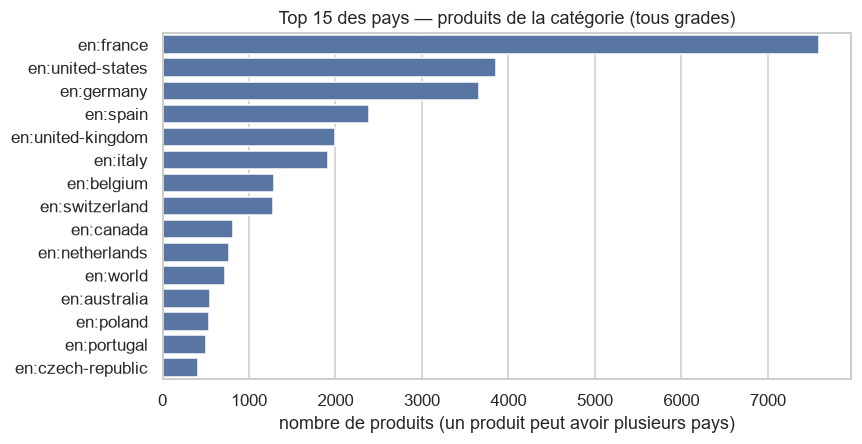

In [7]:
from collections import Counter

country_counter = Counter(x for lst in df_raw["countries_tags"] if lst is not None for x in lst)
country_df = pd.DataFrame(country_counter.most_common(15), columns=["pays", "n"])
country_df["%"] = (100 * country_df["n"] / len(df_raw)).round(1)
display(country_df)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=country_df, y="pays", x="n", color="#4C72B0", ax=ax)
ax.set_title("Top 15 des pays — produits de la catégorie (tous grades)")
ax.set_xlabel("nombre de produits (un produit peut avoir plusieurs pays)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 2. Prétraitement / Nettoyage *(KDD étape 2)*

**Ce que l'on fait.** On mesure la qualité réelle des données (5 contrôles de base, 6 dimensions), on étudie les
valeurs aberrantes et les valeurs manquantes, puis on applique des **règles numérotées et journalisées**.

**Pourquoi.** *Garbage in, garbage out* : un arbre apprend aussi le bruit. Une valeur impossible (sel = 1 333 g/100 g)
ou une ligne sans nutriments fabrique de fausses règles. Chaque suppression doit être justifiée et comptée.

**Notion du cours.** *Prétraitement* : exactitude, complétude, cohérence, unicité, validité, actualité ;
valeurs aberrantes (IQR) ; valeurs manquantes (suppression / imputation) ; traçabilité.

In [8]:
# On travaille sur une copie, avec les noms du contrat de données.
# Attention : le champ OFF `fruits-vegetables-legumes` (fvl_pct) est différent de
# `fruits-vegetables-nuts` (fvn_pct). On garde ce dernier -> colonne `fvl_pct` du contrat.
df = (df_raw
      .drop(columns=["fvl_pct", "fvl_est"])          # évite un doublon de nom après renommage
      .rename(columns={"salt_g": "salt", "fiber": "fibre", "fvn_pct": "fvl_pct"})
      .copy())
df["energy_kj"] = (df["energy_kj_raw"]
                   .fillna(df["energy_kj_field"])
                   .fillna(df["energy_kcal_field"] * 4.184))

print("1) df.shape =", df.shape)
print("\n2) df.info()")
df.info()

1) df.shape = (27940, 32)

2) df.info()
<class 'pandas.DataFrame'>
RangeIndex: 27940 entries, 0 to 27939
Data columns (total 32 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   code                        27940 non-null  str    
 1   name_main                   26715 non-null  str    
 2   name_fr                     9705 non-null   str    
 3   name_any                    27265 non-null  str    
 4   brands                      25780 non-null  str    
 5   countries_tags              27920 non-null  object 
 6   categories_tags             27940 non-null  object 
 7   grade                       27940 non-null  str    
 8   off_score                   23714 non-null  float64
 9   completeness                27940 non-null  float32
 10  last_modified_t             27940 non-null  int64  
 11  created_t                   27940 non-null  int64  
 12  data_quality_errors_tags    27940 non-null  object 
 13  da

In [9]:
print("3) Valeurs manquantes (nombre et %) — 25 colonnes les plus incomplètes")
na = pd.DataFrame({"manquants": df.isna().sum(),
                   "%": (100 * df.isna().mean()).round(1)})
display(na.sort_values("manquants", ascending=False).head(25))

print("4) Doublons")
scalar_cols = [c for c in df.columns if c not in
               ("countries_tags", "categories_tags", "data_quality_errors_tags",
                "data_quality_warnings_tags", "states_tags")]
print("   codes dupliqués            :", int(df["code"].duplicated().sum()))
print("   lignes entièrement dupliquées :", int(df[scalar_cols].duplicated().sum()))

print("\n5) df.describe() (colonnes numériques)")
display(df.select_dtypes("number").describe().T.round(2))

3) Valeurs manquantes (nombre et %) — 25 colonnes les plus incomplètes


,manquants,%
fibers,27940,100.0
energy_kcal_alt,26975,96.5
fvn_est,26671,95.5
name_fr,18235,65.3
fvl_pct,11273,40.3
fibre,6299,22.5
quantity,5737,20.5
off_score,4226,15.1
salt,3626,13.0
sodium_g,3622,13.0


4) Doublons
   codes dupliqués            : 0
   lignes entièrement dupliquées : 0

5) df.describe() (colonnes numériques)


,count,mean,std,min,25%,50%,75%,max
off_score,23714.0,7.080000e+00,7.85,-1.500000e+01,0.000000e+00,8.000000e+00,1.300000e+01,4.100000e+01
completeness,27940.0,6.400000e-01,0.16,1.000000e-01,5.000000e-01,6.800000e-01,7.700000e-01,1.100000e+00
last_modified_t,27940.0,1.769448e+09,29199315.90,1.456948e+09,1.773051e+09,1.774624e+09,1.779768e+09,1.794882e+09
created_t,27940.0,1.618231e+09,92429523.90,1.333715e+09,1.553082e+09,1.617610e+09,1.690921e+09,1.794794e+09
energy_kj_raw,24541.0,1.646970e+03,364.31,0.000000e+00,1.556000e+03,1.645000e+03,1.800000e+03,3.416000e+04
energy_kj_field,24977.0,1.646060e+03,371.38,0.000000e+00,1.555100e+03,1.643700e+03,1.798700e+03,3.416000e+04
energy_kcal_field,25791.0,3.909900e+02,279.84,0.000000e+00,3.684200e+02,3.850000e+02,4.250000e+02,4.300000e+04
energy_kcal_alt,965.0,1.610680e+03,423.94,3.800000e+01,1.530000e+03,1.607000e+03,1.750000e+03,7.890000e+03
sat_fat,25292.0,2.300000e+00,3.26,0.000000e+00,6.000000e-01,1.300000e+00,3.000000e+00,2.657000e+02
sugars,25559.0,1.517000e+01,10.63,0.000000e+00,6.000000e+00,1.500000e+01,2.233000e+01,1.094000e+02


### 2.1 Diagnostic en cinq contrôles — lecture

- **Volume** : 27 940 lignes extraites pour la catégorie (dont les grades `unknown` / `not-applicable`, qui seront
  supprimés par R1).
- **Complétude** : les colonnes d'identité sont complètes ; `fibre` manque dans ~22 % des cas et `fvl_pct` dans ~40 %.
  L'énergie est presque toujours présente (on la reconstitue depuis les kcal si `energy-kj` manque).
- **Doublons** : aucun code-barres dupliqué dans la catégorie (l'extraction agrège déjà par code).
- **Échelle** : les colonnes numériques contiennent des valeurs extrêmes (sel, glucides) qui seront traitées en 2.3.
- **Types** : les listes (`countries_tags`, `categories_tags`) ne sont pas des attributs ; elles seront converties
  en chaînes pour l'export et resteront des métadonnées.

> Le profil `ydata-profiling` est **optionnel** (non requis par la spec) et n'est pas exécuté ici :
> il n'apporterait rien de plus que ces contrôles pour 27 940 lignes.

### 2.2 Les six dimensions de la qualité — indicateurs calculés

| Dimension | Ce que l'on vérifie ici |
|---|---|
| **Exactitude** | valeurs physiquement impossibles : nutriment < 0, > 100 g/100 g, énergie > 3 700 kJ/100 g, énergie incohérente avec les kcal |
| **Complétude** | % de manquants par colonne ; produits sans au moins une des 7 entrées de l'algorithme |
| **Cohérence** | saturés ≤ lipides ; sucres ≤ glucides ; somme des macro-nutriments ≤ 100 g ; sel ≈ sodium × 2,5 ; énergie vs Atwater |
| **Unicité** | codes dupliqués ; lignes identiques ; même produit sous deux codes |
| **Validité** | types, unités, grade ∈ {A…E}, pourcentages dans [0 ; 100] |
| **Actualité** | âge de `last_modified` ; cohérence du couple score/grade avec la version 2015/2021 ou 2023 |

In [10]:
# ---- Exactitude -----------------------------------------------------------
exact = pd.DataFrame([
    ("Nutriment négatif (une des 7 entrées)", int((df[FEATURES] < 0).any(axis=1).sum())),
    ("Énergie > 3 700 kJ/100 g", int((df["energy_kj"] > 3700).sum())),
    ("Énergie incohérente avec kcal × 4,184 (> 20 %)", int((((df["energy_kj"] - df["energy_kcal_field"] * 4.184).abs()
                                                              > 0.2 * df["energy_kj"]) & df["energy_kcal_field"].notna()).sum())),
    ("Saturés > 100 g/100 g", int((df["sat_fat"] > 100).sum())),
    ("Sucres > 100 g/100 g", int((df["sugars"] > 100).sum())),
    ("Sel > 100 g/100 g", int((df["salt"] > 100).sum())),
    ("Protéines > 100 g/100 g", int((df["proteins"] > 100).sum())),
    ("Fibres > 100 g/100 g", int((df["fibre"] > 100).sum())),
    ("fvl_pct hors [0 ; 100]", int(((df["fvl_pct"] < 0) | (df["fvl_pct"] > 100)).sum())),
], columns=["indicateur", "n"])
exact["%"] = (100 * exact["n"] / len(df)).round(2)
display(exact)

,indicateur,n,%
0,Nutriment négatif (une des 7 entrées),10,0.04
1,Énergie > 3 700 kJ/100 g,15,0.05
2,"Énergie incohérente avec kcal × 4,184 (> 20 %)",590,2.11
3,Saturés > 100 g/100 g,2,0.01
4,Sucres > 100 g/100 g,1,0.00
5,Sel > 100 g/100 g,22,0.08
6,Protéines > 100 g/100 g,1,0.00
7,Fibres > 100 g/100 g,0,0.00
8,fvl_pct hors [0 ; 100],44,0.16


In [11]:
# ---- Complétude -----------------------------------------------------------
comp = pd.DataFrame({"manquants": df[FEATURES].isna().sum(),
                     "%": (100 * df[FEATURES].isna().mean()).round(1)})
display(comp)
print("Produits avec au moins une des 7 entrées manquante :",
      int(df[FEATURES].isna().any(axis=1).sum()),
      f"({100 * df[FEATURES].isna().any(axis=1).mean():.1f} %)")
print("Produits complets sur les 7 entrées :",
      int(df[FEATURES].notna().all(axis=1).sum()),
      f"({100 * df[FEATURES].notna().all(axis=1).mean():.1f} %)")

# Alternative « garder NaN + indicateurs » pour fibre / fvl_pct, sur les seuls grades valides
need_n = ["energy_kj", "sat_fat", "sugars", "salt", "proteins"]
valid_grade = df["grade"].isin(list("abcde"))
alt_kept = int(df.loc[valid_grade, need_n].notna().all(axis=1).sum())
complete7 = int(df.loc[valid_grade, FEATURES].notna().all(axis=1).sum())
print(f"Option « garder NaN + indicateurs » (grades valides) : {alt_kept} produits, "
      f"soit {alt_kept - complete7} de plus que la suppression complète.")

,manquants,%
energy_kj,1980,7.1
sat_fat,2648,9.5
sugars,2381,8.5
salt,3626,13.0
fibre,6299,22.5
proteins,2010,7.2
fvl_pct,11273,40.3


Produits avec au moins une des 7 entrées manquante : 12995 (46.5 %)
Produits complets sur les 7 entrées : 14945 (53.5 %)
Option « garder NaN + indicateurs » (grades valides) : 23526 produits, soit 8886 de plus que la suppression complète.


In [12]:
# ---- Cohérence ------------------------------------------------------------
coh = pd.DataFrame([
    ("Saturés > lipides totaux", int((df["sat_fat"] > df["fat"]).sum())),
    ("Sucres > glucides", int((df["sugars"] > df["carbohydrates"]).sum())),
    ("Somme sucres+lipides+protéines+fibres+sel > 105 g", int(((df["sugars"] + df["fat"] + df["proteins"]
                                                                + df["fibre"] + df["salt"]) > 105).sum())),
    ("|sel − 2,5 × sodium| > 0,1 g", int(((df["salt"] - 2.5 * df["sodium_g"]).abs() > 0.1).sum())),
    ("Énergie vs Atwater (écart relatif > 30 %)",
     int((((17 * df["proteins"].fillna(0) + 17 * df["carbohydrates"].fillna(0)
            + 37 * df["fat"].fillna(0) + 8 * df["fibre"].fillna(0)) - df["energy_kj"]).abs()
          > 0.30 * df["energy_kj"]).sum())),
], columns=["indicateur", "n"])
coh["%"] = (100 * coh["n"] / len(df)).round(2)
display(coh)
print("Rapport sel / sodium (médiane) :", round((df["salt"] / df["sodium_g"]).median(), 3))

,indicateur,n,%
0,Saturés > lipides totaux,29,0.10
1,Sucres > glucides,16,0.06
2,Somme sucres+lipides+protéines+fibres+sel > 105 g,44,0.16
3,"|sel − 2,5 × sodium| > 0,1 g",300,1.07
4,Énergie vs Atwater (écart relatif > 30 %),309,1.11


Rapport sel / sodium (médiane) : 2.5


In [13]:
# ---- Unicité --------------------------------------------------------------
print("Codes dupliqués :", int(df["code"].duplicated().sum()))
print("Lignes dupliquées (colonnes scalaires) :", int(df[scalar_cols].duplicated().sum()))
same_subset = ["name_main"] + FEATURES
name_complete = df[same_subset].notna().all(axis=1)
same_product = df.loc[name_complete].duplicated(subset=same_subset, keep=False)
print("Même nom + mêmes nutriments, codes différents :", int(same_product.sum()),
      "(calculé sur les lignes où le nom et les 7 nutriments sont renseignés)")

Codes dupliqués : 0
Lignes dupliquées (colonnes scalaires) : 0
Même nom + mêmes nutriments, codes différents : 421 (calculé sur les lignes où le nom et les 7 nutriments sont renseignés)


In [14]:
# ---- Validité -------------------------------------------------------------
print("Types des 7 attributs :")
print(df[FEATURES].dtypes.to_string())
print("\nGrade dans {a,b,c,d,e} :",
      f"{100 * df['grade'].isin(list('abcde')).mean():.1f} %",
      "| modalités observées :", sorted(df['grade'].dropna().unique()))
fvl_valid = df["fvl_pct"].dropna()
print("fvl_pct dans [0 ; 100] :", f"{100 * fvl_valid.between(0, 100).mean():.1f} % des valeurs renseignées")
print("Unités : énergie = kJ/100 g ; sat_fat, sugars, salt, fibre, proteins = g/100 g ; fvl_pct = %/100 g.")

Types des 7 attributs :
energy_kj    float32
sat_fat      float32
sugars       float32
salt         float32
fibre        float32
proteins     float32
fvl_pct      float32

Grade dans {a,b,c,d,e} : 84.9 % | modalités observées : ['a', 'b', 'c', 'd', 'e', 'not-applicable', 'unknown']
fvl_pct dans [0 ; 100] : 99.7 % des valeurs renseignées
Unités : énergie = kJ/100 g ; sat_fat, sugars, salt, fibre, proteins = g/100 g ; fvl_pct = %/100 g.


In [15]:
# ---- Actualité ------------------------------------------------------------
lm = pd.to_datetime(df["last_modified_t"], unit="s", utc=True)
age_days = (pd.Timestamp.now(tz="UTC") - lm).dt.days
print("Dernière modification :", lm.min().date(), "→", lm.max().date())
print(f"Produits modifiés depuis moins de 12 mois : {100 * (age_days < 365).mean():.1f} %")
print(f"Produits modifiés il y a plus de 3 ans      : {100 * (age_days > 3 * 365).mean():.1f} %")
display(pd.DataFrame({"année": lm.dt.year, "n": 1}).groupby("année").count())

# Cohérence du couple (off_score, grade) avec les deux barèmes : indice de version
# (restreint aux grades valides, sinon les lignes 'unknown' diluent le pourcentage)
valid_grade = df["grade"].isin(list("abcde")) & df["off_score"].notna()
upper = df.loc[valid_grade, "grade"].str.upper()
map23 = df.loc[valid_grade, "off_score"].map(lambda s: grade(s, "2023"))
map21 = df.loc[valid_grade, "off_score"].map(lambda s: grade(s, "2021"))
print(f"\nGrade OFF == barème déduit du score, version 2023 : {100 * (upper == map23).mean():.1f} %")
print(f"Grade OFF == barème déduit du score, version 2021 : {100 * (upper == map21).mean():.1f} %")
print("→ 2023 colle mieux, mais ce test est grossier (les barèmes ne diffèrent qu'à la frontière A/B) :")
print("  la section 5 tranche avec l'égalité exacte des scores, bien plus discriminante.")

Dernière modification : 2016-03-02 → 2026-11-17
Produits modifiés depuis moins de 12 mois : 87.9 %
Produits modifiés il y a plus de 3 ans      : 4.4 %


,n
année,
2016,1
2017,9
2018,8
2019,44
2020,84
2021,110
2022,398
2023,652
2024,963



Grade OFF == barème déduit du score, version 2023 : 99.5 %


Grade OFF == barème déduit du score, version 2021 : 94.4 %
→ 2023 colle mieux, mais ce test est grossier (les barèmes ne diffèrent qu'à la frontière A/B) :
  la section 5 tranche avec l'égalité exacte des scores, bien plus discriminante.


### 2.3 Valeurs aberrantes — méthode IQR et lecture métier

**Définition (cours).** Pour chaque variable : `Q1`, `Q3`, `IQR = Q3 − Q1` ; une valeur est aberrante si elle sort de
`[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]`. C'est une règle **statistique**, pas une règle physique.

**Décision.** On ne supprime **jamais** automatiquement tous les outliers IQR : dans ce projet, les extrêmes sont
souvent de **vraies valeurs rares** (céréales très riches en fibres, produits très sucrés), et ce sont précisément
les cas intéressants pour l'analyse des exceptions. On distingue :

- **Erreur** (valeur physiquement impossible) → correction ou suppression, tracée par R3/R4/R5.
  Exemples : sel = 1 333 g/100 g (unité mg saisie comme g), saturés = 265 g/100 g, énergie = 34 160 kJ/100 g.
- **Valeur réelle rare** → **conservée**. Exemple : 80 g de sucres/100 g dans une céréale au chocolat, 30 g de
  saturés/100 g dans un granola. L'arbre doit pouvoir apprendre sur ces produits.

,variable,Q1,Q3,borne_basse,borne_haute,n_hors_bornes,min,max
0,energy_kj,1554.00,1797.40,1188.90,2162.50,1463,0.00,34160.000000
1,sat_fat,0.60,3.00,-3.00,6.60,1641,0.00,265.700012
2,sugars,6.00,22.33,-18.50,46.83,121,0.00,109.400002
3,salt,0.03,0.68,-0.95,1.66,803,0.00,1333.329956
4,fibre,5.30,10.00,-1.75,17.05,671,0.00,96.000000
5,proteins,7.80,12.00,1.50,18.30,1285,0.00,200.000000
6,fvl_pct,0.00,9.25,-13.87,23.12,1708,-23.98,180.600006


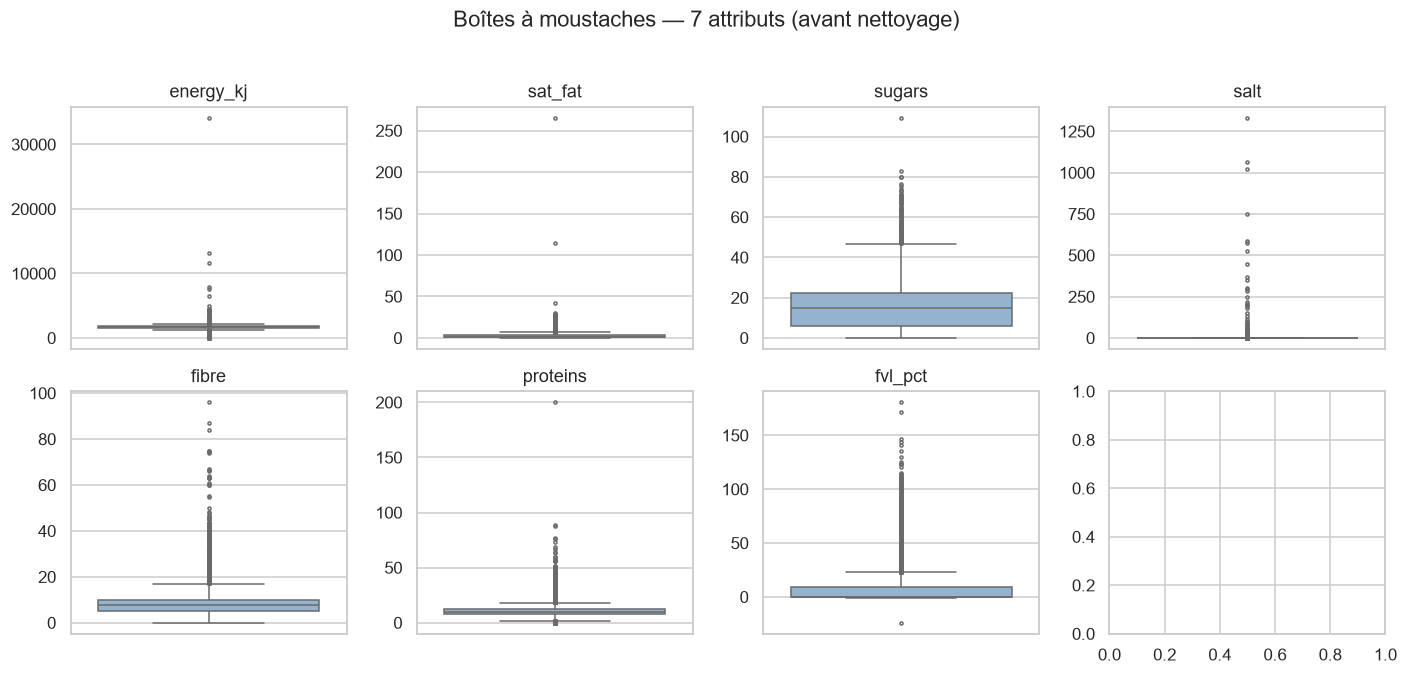

In [16]:
iqr_rows = []
for c in FEATURES:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"variable": c, "Q1": q1, "Q3": q3, "borne_basse": lo, "borne_haute": hi,
                     "n_hors_bornes": int(((df[c] < lo) | (df[c] > hi)).sum()),
                     "min": df[c].min(), "max": df[c].max()})
iqr_df = pd.DataFrame(iqr_rows)
display(iqr_df.round(2))

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[c], ax=ax, color="#8AB4D8", fliersize=2)
    ax.set_title(c)
    ax.set_ylabel("")
fig.suptitle("Boîtes à moustaches — 7 attributs (avant nettoyage)", y=1.02)
plt.tight_layout()
plt.show()

**Lecture des boîtes.** Les variables sont fortement asymétriques à droite (sucres, sel, fibres, protéines) :
la moyenne serait tirée par les extrêmes, la **médiane** est plus robuste (voir 2.4). Les points au-delà des
moustaches ne sont pas tous des erreurs : la table ci-dessus les compte, et les règles R3–R5 ne suppriment que
les valeurs **impossibles**, pas les valeurs rares.

### 2.4 Valeurs manquantes — options du cours et choix

Les options classiques sont : (1) **supprimer** les lignes ou les colonnes incomplètes ; (2) **imputer** par la
moyenne, la médiane ou le mode ; (3) **imputer par un modèle** ; (4) laisser `NaN` et laisser le modèle gérer.

**Choix retenu, et pourquoi :**

1. **Les 4 nutriments « N »** (énergie, saturés, sucres, sel) ne sont **jamais** imputés : une moyenne créerait
   des produits fictifs et fausserait la découverte des seuils. Même raison pour les protéines, les fibres et le
   % fruits/légumes : ce sont les entrées exactes de l'algorithme.
2. On **supprime** les lignes incomplètes sur les 7 entrées (option « suppression »). Le score de référence ne peut
   pas être recalculé sans elles, et les garder obligerait soit à imputer (interdit), soit à laisser 38 % du jeu
   sans score de contrôle.
3. On a envisagé l'option « garder `NaN` + indicateur `*_was_missing` » pour `fibre` et `fvl_pct` : elle conserverait
   **≈ 8 900 produits supplémentaires** (calcul ci-dessus, sur les grades valides), mais rendrait le score non calculable
   pour eux et déplacerait l'imputation vers la partie 2. On documente cette alternative dans `HANDOFF.md` ;
   la suppression complète est plus sûre ici.
4. On **ne calcule aucune statistique d'imputation** (donc aucune fuite) : aucun médiane n'est apprise.

**Médiane plutôt que moyenne** : les distributions sont asymétriques (tableau de *skewness* ci-dessous), la moyenne
est tirée par les valeurs extrêmes. Mais même la médiane n'est pas utilisée pour imputer les entrées de l'algorithme.

In [17]:
skew = pd.DataFrame({"skewness": df[FEATURES].skew(),
                     "moyenne": df[FEATURES].mean(),
                     "médiane": df[FEATURES].median()})
display(skew.round(2))

# Indicateurs de manquants que l'on aurait conservés si l'on gardait les lignes
for c in ("fibre", "fvl_pct"):
    print(f"{c}_was_missing : {int(df[c].isna().sum())} produits")

,skewness,moyenne,médiane
energy_kj,26.900000,1644.890015,1642.00
sat_fat,24.209999,2.300000,1.30
sugars,0.550000,15.170000,15.00
salt,54.509998,0.910000,0.22
fibre,3.640000,7.960000,7.60
proteins,5.260000,10.270000,9.60
fvl_pct,3.490000,7.260000,0.00


fibre_was_missing : 6299 produits
fvl_pct_was_missing : 11273 produits


In [18]:
# Effet de la suppression complète sur la distribution des classes (biais à documenter)
# On se restreint aux grades valides : les 'unknown' / 'not-applicable' sont déjà écartés par R1.
complete = df[FEATURES].notna().all(axis=1)
valid_grade = df["grade"].isin(list("abcde"))
bias = pd.crosstab(df.loc[valid_grade, "grade"].str.upper(),
                   complete.loc[valid_grade], margins=True)
bias.columns = ["incomplet (supprimé)", "complet (conservé)", "Total"]
display(bias)
display((100 * pd.crosstab(df.loc[valid_grade, "grade"].str.upper(),
                           complete.loc[valid_grade], normalize="index")).round(1)
        .rename(columns={False: "% supprimé", True: "% conservé"}))
print("La classe D/E est un peu plus touchée par la suppression : les produits très transformés")
print("renseignent moins souvent fibres et fruits/légumes. C'est une limite à rappeler dans le rapport.")

,incomplet (supprimé),complet (conservé),Total
grade,,,
A,1852,4232,6084
B,774,1157,1931
C,2350,4515,6865
D,3361,3913,7274
E,737,823,1560
All,9074,14640,23714


col_0,% supprimé,% conservé
grade,,
A,30.4,69.6
B,40.1,59.9
C,34.2,65.8
D,46.2,53.8
E,47.2,52.8


La classe D/E est un peu plus touchée par la suppression : les produits très transformés
renseignent moins souvent fibres et fruits/légumes. C'est une limite à rappeler dans le rapport.


### 2.5 Règles de nettoyage explicites

Chaque règle est **numérotée**, **justifiée** et **comptée**. Elles sont implémentées dans une seule fonction
`clean(raw) -> (df, log)` pour que le résultat soit reproductible.

| Règle | Action | Justification |
|---|---|---|
| **R1** | Supprimer les lignes dont le grade n'est pas dans {a,b,c,d,e} (`unknown`, `not-applicable`, nul) | la cible doit être définie ; sinon la ligne ne peut pas servir à l'apprentissage |
| **R2** | Supprimer les doublons de `code` (garder la modification la plus récente) | unicité de l'identifiant ; la fiche la plus récente est la plus fiable |
| **R3** | Supprimer les valeurs négatives sur les entrées de l'algorithme (et le sodium, source de sel) | une quantité négative est physiquement impossible |
| **R4** | Supprimer les valeurs physiquement impossibles : énergie > 3 700 kJ, nutriment > 100 g/100 g, sodium > 40 g/100 g | au-delà, c'est une erreur d'unité ou de saisie, pas un produit réel |
| **R5** | Réconcilier sel et sodium : si `salt` manque, `salt = 2,5 × sodium` ; plafonner `fvl_pct` à 100 % | le sel est l'entrée de l'algorithme 2023 ; le facteur 2,5 est la conversion officielle ; un % > 100 est une estimation d'ingrédients, pas une information nouvelle |
| **R6** | Supprimer les lignes où une des 7 entrées manque | le score de référence ne peut pas être calculé sans les 7 entrées (aucune imputation) |
| **R7** | **Marquer** (sans supprimer) les incohérences : saturés > lipides, sucres > glucides, somme > 105 g, sel ≠ 2,5 × sodium, énergie vs Atwater | une incohérence peut être une vraie erreur d'étiquette, utile pour l'analyse des exceptions |
| **R8** | Renseigner `product_name` manquant par « Produit sans nom » | lisibilité seule ; ce n'est pas un attribut |

**Décision de conception** : `suspect_consistency` conserve les lignes douteuses. On ne supprime pas
silencieusement : on **signale** pour que Yassine puisse les analyser.

In [19]:
def clean(raw: pd.DataFrame):
    '''Applique R1–R8 et renvoie (dataset nettoyé, journal des règles).'''
    d = (raw.drop(columns=["fvl_pct", "fvl_est"])
            .rename(columns={"salt_g": "salt", "fiber": "fibre", "fvn_pct": "fvl_pct"})
            .copy())
    d["energy_kj"] = (d["energy_kj_raw"].fillna(d["energy_kj_field"])
                      .fillna(d["energy_kcal_field"] * 4.184))
    log = []

    def step(rule_id, description, justification, before, after, modified=None):
        log.append({"rule_id": rule_id, "description": description, "justification": justification,
                    "n_rows_before": int(before), "n_rows_after": int(after),
                    "n_modified": int(before - after) if modified is None else int(modified)})

    # R1 — cible valide
    n = len(d)
    d = d[d["grade"].isin(list("abcde"))].copy()
    step("R1", "Supprimer les grades hors {a,b,c,d,e}",
         "La cible doit être définie (unknown / not-applicable / nul exclus).", n, len(d))

    # R2 — unicité du code
    n = len(d)
    d = d.sort_values("last_modified_t").drop_duplicates("code", keep="last")
    step("R2", "Supprimer les doublons de code (garder le plus récent)",
         "Un produit = un code-barres ; la fiche la plus récente est la plus fiable.", n, len(d))

    # R3 — valeurs négatives
    n = len(d)
    neg = (d[FEATURES + ["sodium_g"]] < 0).any(axis=1)
    d = d[~neg].copy()
    step("R3", "Supprimer les valeurs négatives", "Une quantité négative est impossible.", n, len(d))

    # R4 — bornes physiques
    n = len(d)
    violation = ((d["energy_kj"] > 3700) | (d["sat_fat"] > 100) | (d["sugars"] > 100)
                 | (d["salt"] > 100) | (d["proteins"] > 100) | (d["fibre"] > 100)
                 | (d["sodium_g"] > 40))
    d = d[~violation.fillna(False)].copy()
    step("R4", "Supprimer les valeurs physiquement impossibles",
         "Énergie > 3 700 kJ, nutriment > 100 g/100 g ou sodium > 40 g : erreur d'unité ou de saisie.", n, len(d))

    # R5 — réconciliation sel/sodium + plafond fvl
    derived = d["salt"].isna() & d["sodium_g"].notna()
    d.loc[derived, "salt"] = d.loc[derived, "sodium_g"] * 2.5
    d["salt_derived"] = derived
    capped = d["fvl_pct"] > 100
    d.loc[capped, "fvl_pct"] = 100.0
    step("R5", "Réconcilier sel / sodium et plafonner fvl_pct à 100",
         "Sel = 2,5 × sodium (conversion officielle) ; un % > 100 est une estimation, on le borne.",
         len(d), len(d), int(derived.sum() + capped.sum()))

    # R6 — complétude des 7 entrées
    n = len(d)
    missing = d[FEATURES].isna().any(axis=1)
    d = d[~missing].copy()
    step("R6", "Supprimer les lignes incomplètes sur les 7 entrées de l'algorithme",
         "Aucune imputation des entrées du score : un produit fictif fausserait les seuils.", n, len(d))

    # R7 — drapeau de cohérence (on garde les lignes)
    salt_mismatch = (d["salt"] - 2.5 * d["sodium_g"]).abs() > 0.1
    macro_sum = (d["sugars"] + d["fat"] + d["proteins"] + d["fibre"] + d["salt"]) > 105
    atwater = (17 * d["proteins"].fillna(0) + 17 * d["carbohydrates"].fillna(0)
               + 37 * d["fat"].fillna(0) + 8 * d["fibre"].fillna(0))
    energy_mismatch = (atwater - d["energy_kj"]).abs() > 0.30 * d["energy_kj"]
    d["suspect_consistency"] = (salt_mismatch | macro_sum | energy_mismatch
                                | (d["sat_fat"] > d["fat"]) | (d["sugars"] > d["carbohydrates"]))
    step("R7", "Marquer les lignes incohérentes (sans les supprimer)",
         "Une incohérence peut être une vraie erreur d'étiquette : utile pour les exceptions.",
         len(d), len(d), int(d["suspect_consistency"].sum()))

    # R8 — nom lisible
    name = d["name_main"].fillna(d["name_fr"]).fillna(d["name_any"])
    d["product_name"] = name.fillna("Produit sans nom")
    step("R8", "Renseigner les noms manquants",
         "Lisibilité de l'analyse des exceptions ; product_name n'est pas un attribut.",
         len(d), len(d), int(name.isna().sum()))

    d["any_nutrient_was_imputed"] = d["salt_derived"].astype(bool)

    # Ordre canonique (code croissant) : le split dépend de l'ordre des lignes.
    # DuckDB peut renvoyer le sous-ensemble dans un ordre différent après reconstruction ;
    # ce tri garantit que clean() puis train_test_split() donnent toujours les mêmes ensembles.
    d = d.sort_values("code").reset_index(drop=True)
    return d, pd.DataFrame(log)


df_clean, cleaning_log = clean(df_raw)
print("Dataset nettoyé :", df_clean.shape)
print("Lignes supprimées :", len(df_raw) - len(df_clean), f"({100 * (1 - len(df_clean) / len(df_raw)):.1f} %)")
display(cleaning_log)

Dataset nettoyé : (14611, 36)
Lignes supprimées : 13329 (47.7 %)


,rule_id,description,justification,n_rows_before,n_rows_after,n_modified
0,R1,"Supprimer les grades hors {a,b,c,d,e}",La cible doit être définie (unknown / not-appl...,27940,23714,4226
1,R2,Supprimer les doublons de code (garder le plus...,Un produit = un code-barres ; la fiche la plus...,23714,23714,0
2,R3,Supprimer les valeurs négatives,Une quantité négative est impossible.,23714,23704,10
3,R4,Supprimer les valeurs physiquement impossibles,"Énergie > 3 700 kJ, nutriment > 100 g/100 g ou...",23704,23669,35
4,R5,Réconcilier sel / sodium et plafonner fvl_pct ...,"Sel = 2,5 × sodium (conversion officielle) ; u...",23669,23669,34
5,R6,Supprimer les lignes incomplètes sur les 7 ent...,Aucune imputation des entrées du score : un pr...,23669,14611,9058
6,R7,Marquer les lignes incohérentes (sans les supp...,Une incohérence peut être une vraie erreur d'é...,14611,14611,417
7,R8,Renseigner les noms manquants,Lisibilité de l'analyse des exceptions ; produ...,14611,14611,112


In [20]:
# Journal exporté (livrable n°4)
cleaning_log.to_csv(PROCESSED / "cleaning_log.csv", index=False)
print("Écrit :", (PROCESSED / "cleaning_log.csv").name)

with pd.option_context("display.max_colwidth", 80):
    display(cleaning_log[["rule_id", "description", "n_rows_before", "n_rows_after", "n_modified"]])

Écrit : cleaning_log.csv


,rule_id,description,n_rows_before,n_rows_after,n_modified
0,R1,"Supprimer les grades hors {a,b,c,d,e}",27940,23714,4226
1,R2,Supprimer les doublons de code (garder le plus récent),23714,23714,0
2,R3,Supprimer les valeurs négatives,23714,23704,10
3,R4,Supprimer les valeurs physiquement impossibles,23704,23669,35
4,R5,Réconcilier sel / sodium et plafonner fvl_pct à 100,23669,23669,34
5,R6,Supprimer les lignes incomplètes sur les 7 entrées de l'algorithme,23669,14611,9058
6,R7,Marquer les lignes incohérentes (sans les supprimer),14611,14611,417
7,R8,Renseigner les noms manquants,14611,14611,112


In [21]:
# Reproductibilité : on relance clean() depuis le sous-ensemble brut et on compare forme + hash.
HASH_COLS = ["code", "energy_kj", "sat_fat", "sugars", "salt", "fibre", "proteins",
             "fvl_pct", "grade", "off_score"]

def frame_hash(frame):
    obj = frame.sort_values("code")[HASH_COLS].reset_index(drop=True)
    return hashlib.sha256(pd.util.hash_pandas_object(obj, index=False).to_numpy().tobytes()).hexdigest()

df_clean_2, log_2 = clean(df_raw)
h1, h2 = frame_hash(df_clean), frame_hash(df_clean_2)
print("hash 1 :", h1[:32])
print("hash 2 :", h2[:32])
assert df_clean.shape == df_clean_2.shape
assert h1 == h2
assert cleaning_log["n_modified"].tolist() == log_2["n_modified"].tolist()
print("OK : clean() est déterministe (même forme, même hash, mêmes compteurs).")

hash 1 : 8cec3aaabd3159e467e7c53cf8147211
hash 2 : 8cec3aaabd3159e467e7c53cf8147211
OK : clean() est déterministe (même forme, même hash, mêmes compteurs).


**Lecture du journal.** Les pertes se concentrent sur **R6 (complétude)** : sans imputation, un produit qui n'a pas
de fibres ou de % fruits/légumes ne peut pas recevoir de score de référence. C'est le prix de la rigueur :
on préfère 14 611 produits **complets et vérifiables** aux 23 714 produits à grade valide, dont 38 % n'ont pas
les 7 entrées nécessaires. Les règles R3–R5 ne touchent que quelques dizaines de lignes : les valeurs impossibles
sont rares mais réelles.

## 3. Transformation *(KDD étape 3)*

**Ce que l'on fait.** On construit le jeu final avec **exactement 7 attributs** et la cible ordinale, on documente
les unités, et on vérifie la distribution des classes.

**Pourquoi.** L'arbre de décision n'a besoin ni de normalisation ni de one-hot ; en revanche il a besoin de variables
dans les bonnes unités et d'une cible encodée de façon cohérente (A=0 … E=4).

**Notion du cours.** *Transformation* : recodage, discrétisation éventuelle, normalisation (inutile pour un arbre),
réduction de dimension, sélection d'attributs.

In [22]:
data = df_clean.copy()
data["grade"] = pd.Categorical(data["grade"].str.upper(), categories=GRADES, ordered=True)
data["y_int"] = data["grade"].cat.codes.astype("int8")
data["off_score"] = data["off_score"].astype(float)
data["countries"] = data["countries_tags"].apply(
    lambda x: "|".join(str(v) for v in x) if x is not None and len(x) > 0 else ""
)
data["last_modified"] = pd.to_datetime(data["last_modified_t"], unit="s", utc=True)

# Contrôles de domaine : toutes les valeurs sont dans les bornes physiques
assert (data["energy_kj"].between(0, 3700)).all()
assert (data[["sat_fat", "sugars", "salt", "fibre", "proteins"]].ge(0).all().all())
assert (data[["sat_fat", "sugars", "salt", "fibre", "proteins"]].le(100).all().all())
assert (data["fvl_pct"].between(0, 100)).all()
assert data[FEATURES].notna().all().all()
assert (data["y_int"] >= 0).all() and (data["y_int"] <= 4).all()

print("data :", data.shape)
print("Aucune valeur manquante sur les 7 attributs :", not data[FEATURES].isna().any().any())
display(data[FEATURES + ["grade", "y_int"]].head())

data : (14611, 39)
Aucune valeur manquante sur les 7 attributs : True


,energy_kj,sat_fat,sugars,salt,fibre,proteins,fvl_pct,grade,y_int
0,1174.000000,1.400000,16.000000,0.090000,7.300000,10.000000,11.036875,A,0
1,304.964996,0.043675,16.188999,0.002464,0.736500,0.478300,26.000000,C,2
2,1575.000000,4.100000,16.000000,0.010000,8.900000,11.000000,34.250000,C,2
3,1798.275879,0.000000,20.689655,0.991379,10.344828,6.896552,0.000000,C,2
4,1448.000000,0.300000,0.600000,0.080000,3.600000,7.000000,0.000000,B,1


,classe,n,%
0,A,4230,29.0
1,B,1157,7.9
2,C,4508,30.9
3,D,3907,26.7
4,E,809,5.5


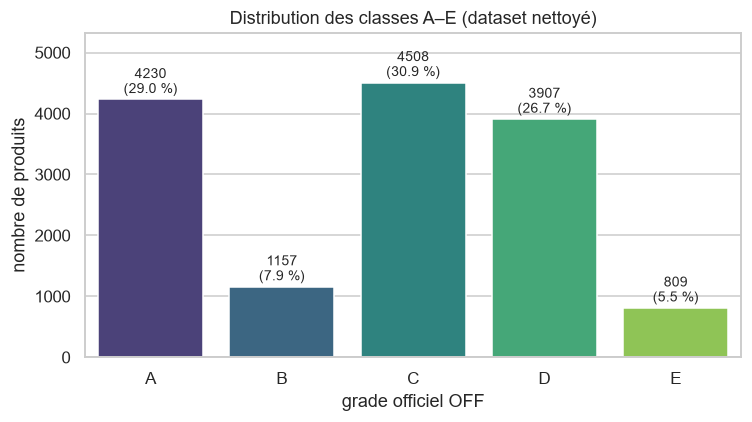

In [23]:
counts = data["grade"].value_counts().reindex(GRADES)
freq = (100 * counts / len(data)).round(1)
class_df = pd.DataFrame({"classe": GRADES, "n": counts.values, "%": freq.values})
display(class_df)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=class_df, x="classe", y="n", hue="classe", palette="viridis", legend=False, ax=ax)
for i, row in class_df.iterrows():
    ax.text(i, row["n"] + 40, f'{row["n"]}\n({row["%"]} %)', ha="center", va="bottom", fontsize=9)
ax.set_title("Distribution des classes A–E (dataset nettoyé)")
ax.set_ylabel("nombre de produits")
ax.set_xlabel("grade officiel OFF")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

**Déséquilibre.** Les classes A, C et D dominent ; B et E sont minoritaires (≈ 8 % et ≈ 6 %). Un modèle qui prédit
toujours la classe majoritaire aurait une *accuracy* trompeuse. **Conséquence pour Yassine** : utiliser le
**F1 macro**, le **rappel par classe** et la **matrice de confusion**, pas l'accuracy seule. On ne rééquilibre pas
ici : le rééchantillonnage est une décision de modélisation (partie 2), et il devrait être appris sur le train seulement.

**Pas de normalisation** : un arbre de décision découpe chaque variable par des seuils (`x ≤ s`) ; multiplier une
variable par une constante ne change pas les découpages possibles. **Pas de one-hot** : les 7 attributs sont
quantitatifs et la cible est ordinale (`y_int`), pas nominale.

In [24]:
stats = data[FEATURES].describe().T
stats["skewness"] = data[FEATURES].skew().round(2)
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
energy_kj,14611.0,1658.30,277.39,0.0,1566.40,1659.00,1813.00,3525.0,-2.110000
sat_fat,14611.0,2.22,2.57,0.0,0.60,1.30,3.00,30.0,2.730000
sugars,14611.0,15.43,10.32,0.0,6.70,16.00,22.50,80.0,0.350000
salt,14611.0,0.48,1.67,0.0,0.03,0.22,0.67,82.5,31.049999
fibre,14611.0,7.94,4.64,0.0,5.40,7.60,9.94,96.0,3.540000
proteins,14611.0,10.33,4.77,0.0,7.90,9.60,12.00,89.0,3.450000
fvl_pct,14611.0,7.32,13.50,0.0,0.00,0.00,9.51,100.0,3.100000


## 4. Séparation train / validation / test *(avant toute statistique apprise)*

**La règle du cours.** *Toute étape qui calcule une statistique vient après la séparation.* Le jeu de test est
**sacré** : il ne sert ni à l'entraînement ni au réglage, une seule fois à la fin.

**Pourquoi maintenant.** Si l'on calculait une moyenne, une médiane d'imputation ou une sélection de variables sur
l'ensemble des données, le test influencerait l'apprentissage : c'est une **fuite de données** (*leakage*).
Exemple concret dans ce projet : utiliser `off_score` comme attribut revient à donner la réponse au modèle.

**Trois sens du mot « échantillonnage »** :

1. **Échantillon de population** : les produits OFF sont un échantillon de convenance de la population des produits.
2. **Découpage** : train / validation / test, pour mesurer la généralisation.
3. **Rééquilibrage** : sur-échantillonnage ou sous-échantillonnage des classes (non fait ici).

La stratification (`stratify=y`) conserve les proportions A–E dans chaque sous-ensemble ; c'est la pratique la plus
courante en Data Mining. On utilise 70 / 15 / 15 : assez de train, et un test suffisamment grand pour être stable.

In [25]:
train, temp = train_test_split(data, test_size=0.30, stratify=data["y_int"], random_state=RANDOM_STATE)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["y_int"], random_state=RANDOM_STATE)

print("Tailles :", {"train": len(train), "val": len(val), "test": len(test), "total": len(data)})
assert len(train) + len(val) + len(test) == len(data)
assert set(train["code"]).isdisjoint(set(val["code"]))
assert set(train["code"]).isdisjoint(set(test["code"]))
assert set(val["code"]).isdisjoint(set(test["code"]))
print("Aucun code commun entre les trois ensembles.")

props = pd.DataFrame({
    "train": train["grade"].value_counts(normalize=True).reindex(GRADES),
    "val": val["grade"].value_counts(normalize=True).reindex(GRADES),
    "test": test["grade"].value_counts(normalize=True).reindex(GRADES),
}).round(4) * 100
props["écart max (pts)"] = (props.max(axis=1) - props.min(axis=1)).round(2)
display(props)
assert (props["écart max (pts)"] < 1.0).all()
print("OK : proportions à moins de 1 point d'écart entre les trois ensembles.")

Tailles : {'train': 10227, 'val': 2192, 'test': 2192, 'total': 14611}
Aucun code commun entre les trois ensembles.


,train,val,test,écart max (pts)
grade,,,,
A,28.95,28.92,28.97,0.05
B,7.92,7.94,7.89,0.05
C,30.85,30.84,30.89,0.05
D,26.74,26.73,26.73,0.01
E,5.53,5.57,5.52,0.05


OK : proportions à moins de 1 point d'écart entre les trois ensembles.


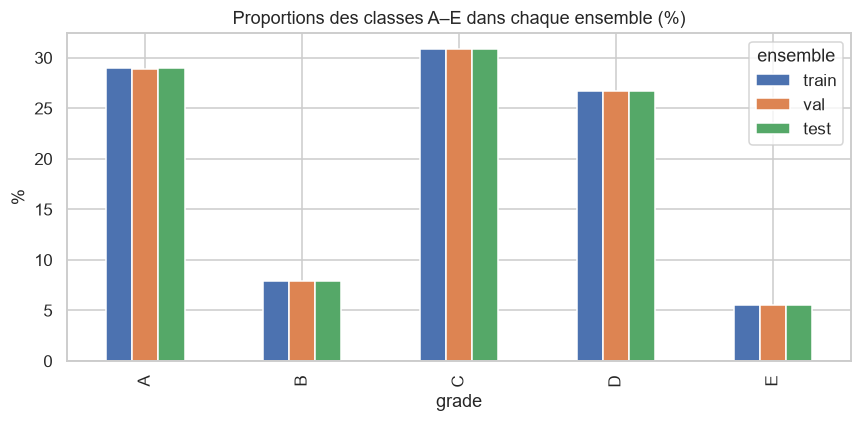

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
props[["train", "val", "test"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Proportions des classes A–E dans chaque ensemble (%)")
ax.set_ylabel("%")
ax.set_xlabel("grade")
ax.legend(title="ensemble")
plt.tight_layout()
plt.show()

> **Si un sous-échantillon de travail était nécessaire**, l'idiome pandas du cours serait
> `data.groupby("grade", observed=True).sample(frac=0.1, random_state=42)` — un tirage **stratifié**.
> Ici le volume (≈ 14 600 lignes) ne le justifie pas : on travaille sur tout le dataset nettoyé.

### 4.1 Sélection d'attributs — uniquement sur le train

**Notions du cours.** La **sélection** garde un sous-ensemble des variables ; la **réduction de dimension**
(ACP, etc.) crée de nouvelles variables. Trois familles : **filtres** (corrélation, information mutuelle),
**wrappers** (avant/arrière), **embedded** (Lasso, importance d'un arbre).

On calcule la matrice de corrélation et l'information mutuelle **sur le train seulement** : ce sont des statistiques
apprises, elles n'ont pas le droit de voir val/test. Conclusion attendue : on garde les 7 attributs, car ce sont
**exactement les entrées de l'algorithme** ; les supprimer détruirait la capacité à redécouvrir les seuils.

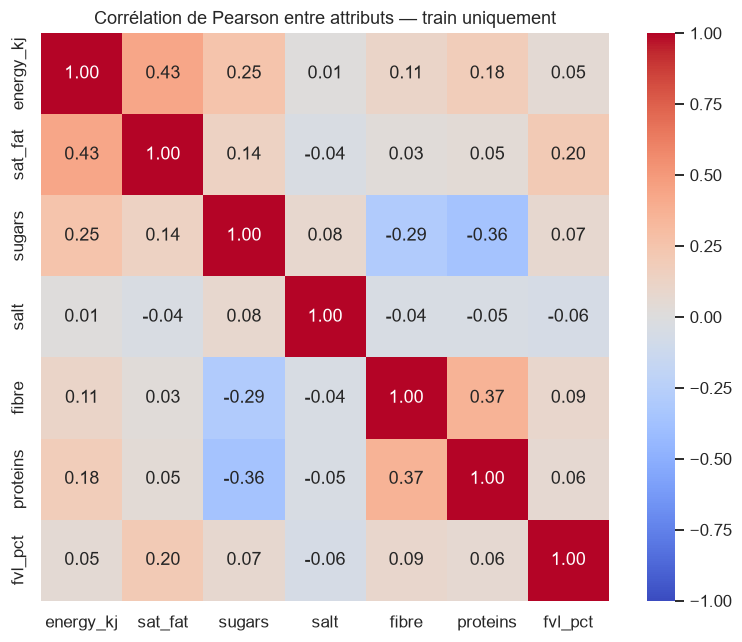

Paires avec |r| >= 0,99 : aucune


,attribut,information mutuelle
2,sugars,0.4753
5,proteins,0.3057
3,salt,0.2998
4,fibre,0.2662
0,energy_kj,0.2552
1,sat_fat,0.2229
6,fvl_pct,0.0375


In [27]:
corr = train[FEATURES].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Corrélation de Pearson entre attributs — train uniquement")
plt.tight_layout()
plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
         if abs(corr.loc[a, b]) >= 0.99]
print("Paires avec |r| >= 0,99 :", pairs if pairs else "aucune")

mi = mutual_info_classif(train[FEATURES], train["y_int"],
                         discrete_features=False, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({"attribut": FEATURES, "information mutuelle": mi}).sort_values(
    "information mutuelle", ascending=False)
display(mi_df.round(4))

**Conclusion.** Aucune paire n'atteint |r| ≥ 0,99 : il n'y a pas de redondance quasi parfaite à éliminer.
L'information mutuelle classe les attributs par utilité, mais on **conserve les 7** : ce sont les variables de
l'algorithme officiel, et l'objectif est justement de retrouver leur rôle et leurs seuils. Une sélection agressive
rendrait l'arbre moins interprétable et empêcherait la comparaison avec les règles du Nutri-Score.

In [28]:
# Illustration PEDAGOGIQUE : un pipeline d'imputation, ajusté sur le train uniquement.
# Il n'est PAS appliqué aux données sauvegardées (aucune valeur manquante dans le jeu final).
demo_pipeline = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), list(FEATURES)),
    ]))
])
demo_pipeline.fit(train[list(FEATURES)])
medians = demo_pipeline.named_steps["prep"].named_transformers_["num"].named_steps["imputer"].statistics_
display(pd.DataFrame({"attribut": FEATURES, "médiane apprise (train)": medians.round(2)}))
print("Ce pipeline est une documentation : les fichiers exportés ne sont PAS imputés.")

,attribut,médiane apprise (train)
0,energy_kj,1658.75
1,sat_fat,1.30
2,sugars,16.00
3,salt,0.22
4,fibre,7.60
5,proteins,9.60
6,fvl_pct,0.00


Ce pipeline est une documentation : les fichiers exportés ne sont PAS imputés.


## 5. Calculateur Nutri-Score de référence + validation

**L'algorithme en mots.** On calcule des **points négatifs N** (énergie, acides gras saturés, sucres, sel) et des
**points positifs P** (fibres, protéines, fruits/légumes/légumineuses).

- **2023 (général)** : N max 55 (énergie 10, saturés 10, sucres 15, sel 20) ; P max 17 (fibres 5, protéines 7,
  fruits/légumes 5). Si **N < 11** → score = N − (fibres + protéines + fruits/légumes) ; si **N ≥ 11** → les
  protéines ne comptent plus : score = N − (fibres + fruits/légumes). Fromage : protéines toujours comptées.
  Viande rouge : protéines plafonnées à 2 points. Notes : A ≤ 0, B 1–2, C 3–10, D 11–18, E ≥ 19.
- **2015/2021** : N max 40 (énergie 10, saturés 10, sucres 10, **sodium** 10) ; P max 15 (fibres 5, protéines 5,
  fruits/légumes 5). Conversion `sodium_mg = sel_g × 400`. Si N ≥ 11, les protéines ne comptent **que si** les
  fruits/légumes valent 5 points (exemption supprimée en 2023). Notes : A ≤ −1, B 0–2, C 3–10, D 11–18, E ≥ 19.

**Vérification importante — la table de l'énoncé était décalée.** L'énoncé place les lignes 6 et 7 points
(> 14 g, > 17 g) dans la colonne **fibres** et plafonne les protéines à 5. L'**arrêté du 14 mars 2025**
(JORFTEXT000051329233, tables du cas général) montre l'inverse : **fibres max 5** (> 7,4 g), **protéines max 7**
(> 14 g puis > 17 g). L'API OFF le confirme (`nutriscore_data.components` : `points_max = 5` pour les fibres).
On implémente donc **fibres 5 / protéines 7** ; c'est cette version qui maximise l'accord avec OFF (voir plus bas).

In [29]:
T = load_thresholds()
print("Versions disponibles :", list(T.keys()))
for version in ("2023", "2021"):
    print(f"\n--- {version} ---")
    for key in ("energy_kj", "saturated_fat_g", "sugars_g", "salt_g", "sodium_mg",
                "fibre_g", "protein_g", "fvl_pct"):
        if key in T[version]:
            print(f"{key:16s}: {T[version][key]}")
    print("règles          :", T[version]["rules"])
    print("notes           :", T[version]["grades"])

Versions disponibles : ['2023', '2021']

--- 2023 ---
energy_kj       : [335, 670, 1005, 1340, 1675, 2010, 2345, 2680, 3015, 3350]
saturated_fat_g : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
sugars_g        : [3.4, 6.8, 10, 14, 17, 20, 24, 27, 31, 34, 37, 41, 44, 48, 51]
salt_g          : [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0]
fibre_g         : [3.0, 4.1, 5.2, 6.3, 7.4]
protein_g       : [2.4, 4.8, 7.2, 9.6, 12, 14, 17]
fvl_pct         : {'thresholds': [40, 60, 80], 'points': [1, 2, 5]}
règles          : {'protein_cutoff_n': 11, 'protein_always_for_cheese': True, 'red_meat_protein_cap': 2}
notes           : {'A_max': 0, 'B_max': 2, 'C_max': 10, 'D_max': 18}

--- 2021 ---
energy_kj       : [335, 670, 1005, 1340, 1675, 2010, 2345, 2680, 3015, 3350]
saturated_fat_g : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
sugars_g        : [4.5, 9, 13.5, 18, 22.5, 27, 31, 36, 40, 45]
sodium_mg       : [90, 180, 270, 360, 450, 540, 630, 720, 810, 900]
fibre_g   

In [30]:
# ------------------------- TESTS UNITAIRES DU CALCULATEUR -------------------------
from src.nutriscore import fvl_points, points

# 1) Convention : une valeur exactement au seuil donne le point inférieur
assert points(335, T["2023"]["energy_kj"]) == 0
assert points(335.01, T["2023"]["energy_kj"]) == 1
assert points(3350, T["2023"]["energy_kj"]) == 9
assert points(3350.01, T["2023"]["energy_kj"]) == 10
assert points(3.4, T["2023"]["sugars_g"]) == 0 and points(3.41, T["2023"]["sugars_g"]) == 1
assert points(51.0, T["2023"]["sugars_g"]) == 14 and points(51.01, T["2023"]["sugars_g"]) == 15
assert points(4.0, T["2023"]["salt_g"]) == 19 and points(4.01, T["2023"]["salt_g"]) == 20
assert points(3.0, T["2023"]["fibre_g"]) == 0 and points(7.5, T["2023"]["fibre_g"]) == 5
assert points(12.0, T["2023"]["protein_g"]) == 4 and points(14.1, T["2023"]["protein_g"]) == 6

# 2) Fruits/légumes : échelle non linéaire
assert fvl_points(40, T["2023"]["fvl_pct"]) == 0
assert fvl_points(40.1, T["2023"]["fvl_pct"]) == 1
assert fvl_points(60.1, T["2023"]["fvl_pct"]) == 2
assert fvl_points(80.1, T["2023"]["fvl_pct"]) == 5

# 3) Bascule N = 10 / N = 11 (protéines comptées ou non)
n10 = dict(energy_kj=3350, sat_fat=1.01, sugars=0, salt=0, fibre=10, proteins=20, fvl_pct=90)
n11 = dict(n10, sat_fat=2.01)
assert compute(n10, "2023")["N"] == 10 and compute(n10, "2023")["protein_counted"] is True
assert compute(n11, "2023")["N"] == 11 and compute(n11, "2023")["protein_counted"] is False
assert compute(n11, "2023")["score"] == 11 - (5 + 5)

# 4) Fromage : protéines toujours comptées
assert compute(n11, "2023", cheese=True)["protein_counted"] is True
assert compute(n11, "2023", cheese=True)["score"] == 11 - (5 + 7 + 5)

# 5) Viande rouge 2023 : protéines plafonnées à 2 (visible seulement si N < 11)
assert compute(n10, "2023", red_meat=True)["score"] == 10 - (5 + 2 + 5)

# 6) 2021 : conversion sel -> sodium (900 mg pile = 9 points, 904 mg = 10)
assert points(2.25 * 400, T["2021"]["sodium_mg"]) == 9
assert points(2.26 * 400, T["2021"]["sodium_mg"]) == 10

# 7) Bornes des notes, par version
for version, mapping in [("2023", {0: "A", 1: "B", 2: "B", 3: "C", 10: "C", 11: "D", 18: "D", 19: "E"}),
                         ("2021", {-1: "A", 0: "B", 2: "B", 3: "C", 10: "C", 11: "D", 18: "D", 19: "E"})]:
    for s, expected in mapping.items():
        assert grade(s, version) == expected, (version, s)
print("Tous les tests unitaires passent (seuils, N=10/11, fromage, viande rouge, conversion sodium, notes).")

Tous les tests unitaires passent (seuils, N=10/11, fromage, viande rouge, conversion sodium, notes).


In [31]:
# Application du calculateur, sur chaque ensemble, sans aucune statistique apprise
def add_calculator_columns(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    rows = []
    for values in out[list(FEATURES)].itertuples(index=False):
        x = dict(zip(FEATURES, values))
        r23 = compute(x, "2023")
        r21 = compute(x, "2021")
        rows.append((r21["score"], r21["grade"], r23["score"], r23["grade"]))
    out[["score_v2021", "grade_v2021", "score_v2023", "grade_v2023"]] = pd.DataFrame(
        rows, index=out.index, columns=["score_v2021", "grade_v2021", "score_v2023", "grade_v2023"])
    out["agrees_with_off_v2021"] = out["grade_v2021"] == out["grade"].astype(str)
    out["agrees_with_off_v2023"] = out["grade_v2023"] == out["grade"].astype(str)

    s21, s23, off_s = out["score_v2021"], out["score_v2023"], out["off_score"]
    both = (s21 == off_s) & (s23 == off_s)
    only21 = (s21 == off_s) & ~both
    only23 = (s23 == off_s) & ~both
    out["nutriscore_version_guess"] = np.select(
        [both, only21, only23], ["2021+2023", "2021", "2023"], default="unknown")
    return out


train = add_calculator_columns(train)
val = add_calculator_columns(val)
test = add_calculator_columns(test)
display(train[["code", "grade", "off_score", "score_v2021", "grade_v2021", "score_v2023", "grade_v2023"]].head())

,code,grade,off_score,score_v2021,grade_v2021,score_v2023,grade_v2023
11602,7501008005934,A,0.0,-2,A,0,A
7122,4088600025582,A,-2.0,-3,A,-2,A
9573,5059319007649,C,8.0,0,B,8,C
10206,5400113611257,A,-1.0,-6,A,-1,A
8695,50104773012246,B,2.0,-2,A,1,B


,version,score exact (%),|écart| moyen,grade identique (%)
0,2021,8.77,3.31,55.79
1,2023,89.02,0.21,97.49


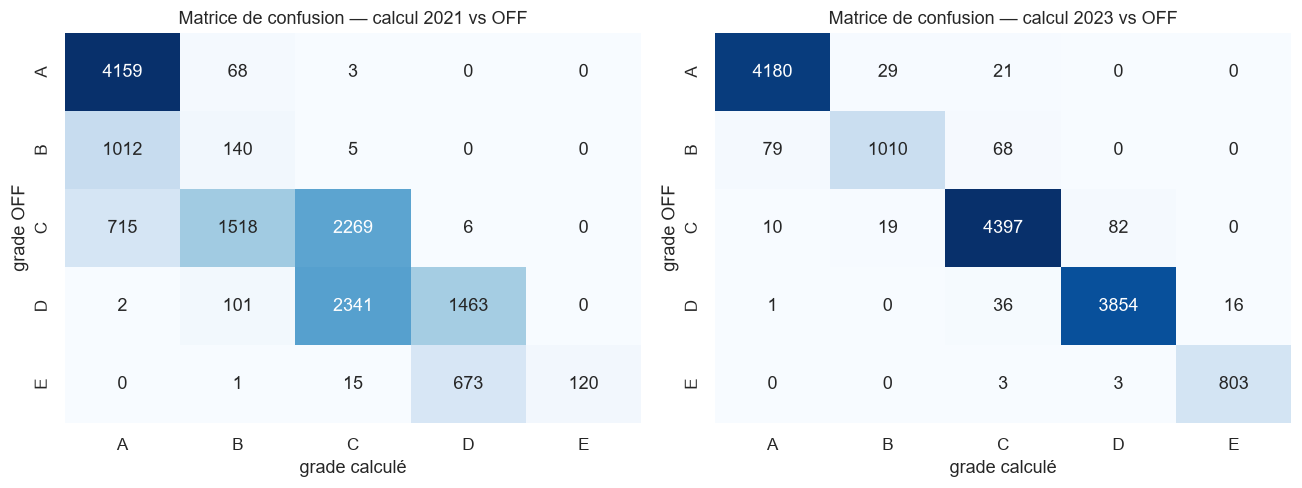

In [32]:
all_scored = pd.concat([train, val, test], ignore_index=True)
off_grade = all_scored["grade"].astype(str)

agreement = []
for version in ("2021", "2023"):
    s = all_scored[f"score_v{version}"]
    g = all_scored[f"grade_v{version}"]
    agreement.append({
        "version": version,
        "score exact (%)": round(100 * (s == all_scored["off_score"]).mean(), 2),
        "|écart| moyen": round((s - all_scored["off_score"]).abs().mean(), 2),
        "grade identique (%)": round(100 * (g == off_grade).mean(), 2),
    })
agreement_df = pd.DataFrame(agreement)
display(agreement_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, version in zip(axes, ("2021", "2023")):
    cm = pd.crosstab(off_grade, all_scored[f"grade_v{version}"])
    cm = cm.reindex(index=GRADES, columns=GRADES, fill_value=0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"Matrice de confusion — calcul {version} vs OFF")
    ax.set_xlabel("grade calculé")
    ax.set_ylabel("grade OFF")
plt.tight_layout()
plt.show()

In [33]:
# VERIFY : la table de l'énoncé (fibres max 7, protéines max 5) est-elle meilleure ?
# On recalcule le score 2023 avec cette lecture et on compare à OFF.
BRIEF_TABLE = dict(T["2023"])
BRIEF_TABLE["fibre_g"] = [3.0, 4.1, 5.2, 6.3, 7.4, 14, 17]
BRIEF_TABLE["protein_g"] = [2.4, 4.8, 7.2, 9.6, 12]

def score_2023_with(table, row):
    N = (points(row.energy_kj, table["energy_kj"])
         + points(row.sat_fat, table["saturated_fat_g"])
         + points(row.sugars, table["sugars_g"])
         + points(row.salt, table["salt_g"]))
    f = points(row.fibre, table["fibre_g"])
    p = points(row.proteins, table["protein_g"])
    v = fvl_points(row.fvl_pct, table["fvl_pct"])
    return int(N - (v + f + p if N < 11 else v + f))

off_s = all_scored["off_score"]
alt_scores = all_scored.apply(lambda r: score_2023_with(BRIEF_TABLE, r), axis=1)
alt_grades = alt_scores.map(lambda s: grade(s, "2023"))
print(f"Table de l'énoncé (fibres 7 / protéines 5) : {100 * (alt_scores == off_s).mean():.2f} % de scores exacts, "
      f"{100 * (alt_grades == off_grade).mean():.2f} % de notes identiques")
print(f"Table vérifiée   (fibres 5 / protéines 7) : {100 * (all_scored['score_v2023'] == off_s).mean():.2f} % de scores exacts, "
      f"{100 * (all_scored['grade_v2023'] == off_grade).mean():.2f} % de notes identiques")
print("→ la correction de l'arrêté (fibres 5 / protéines 7) est bien celle qui reproduit le mieux OFF.")


Table de l'énoncé (fibres 7 / protéines 5) : 81.61 % de scores exacts, 96.63 % de notes identiques
Table vérifiée   (fibres 5 / protéines 7) : 89.02 % de scores exacts, 97.49 % de notes identiques
→ la correction de l'arrêté (fibres 5 / protéines 7) est bien celle qui reproduit le mieux OFF.


**Lecture.** L'accord est **très élevé pour 2023** (≈ 97,5 % de lettres identiques, ≈ 89 % de scores exacts,
écart moyen ≈ 0,2 point) et **faible pour 2021** : le snapshot OFF est majoritairement noté avec le nouvel
algorithme, ce qui est cohérent avec l'obligation de bascule (nouveaux produits depuis fin 2023, transition
jusqu'à fin 2025).

Les désaccords restants ne sont pas des bugs du calculateur. Causes identifiées :

1. **Version mixte** : une minorité de fiches garde un score 2015/2021.
2. **Fruits/légumes estimés autrement** : OFF estime parfois le % à partir des ingrédients, alors que l'on utilise
   le champ déclaré `fruits-vegetables-nuts` (rempli à ~60 % des lignes de la catégorie, l'estimation n'étant présente
   que dans ~4 % des lignes). C'est la première cause des écarts de plusieurs points.
3. **Arrondis et millésime** : OFF peut avoir recalculé le score après une modification de fiche ; le score stocké
   et les nutriments stockés ne proviennent pas forcément de la même révision.
4. **Erreurs d'étiquette** : c'est précisément la liste d'exceptions à analyser en partie 2.

**Ces désaccords sont une richesse**, pas un échec : ils constituent la première liste d'exceptions.

In [34]:
# Version probable du score OFF, déduite de l'égalité exacte avec l'un des deux calculs
# (la colonne a été créée par add_calculator_columns, avec la priorité : les deux -> "2021+2023")
display(all_scored["nutriscore_version_guess"].value_counts().to_frame("n"))
print("Total :", len(all_scored))

,n
nutriscore_version_guess,
2023,11796
unknown,1534
2021+2023,1210
2021,71


Total : 14611


In [35]:
# Export de la liste d'exceptions "calculateur" (livrable pour Yassine)
off_s = all_scored["off_score"]
off_grade = all_scored["grade"].astype(str)
best_ok = (((all_scored["score_v2023"] == off_s) & (all_scored["grade_v2023"] == off_grade))
           | ((all_scored["score_v2021"] == off_s) & (all_scored["grade_v2021"] == off_grade)))
disagreements = all_scored.loc[~best_ok].copy()
cols_dis = ["code", "product_name", "grade", "off_score", "score_v2021", "grade_v2021",
            "score_v2023", "grade_v2023", "nutriscore_version_guess", "suspect_consistency",
            "countries"] + list(FEATURES)
disagreements[cols_dis].to_parquet(PROCESSED / "calculator_disagreements.parquet", index=False)
print("calculator_disagreements.parquet :", disagreements.shape[0], "lignes",
      f"({100 * len(disagreements) / len(all_scored):.1f} % du jeu)")
display(disagreements[cols_dis].head())

calculator_disagreements.parquet : 1548 lignes (10.6 % du jeu)


,code,product_name,grade,off_score,score_v2021,grade_v2021,score_v2023,grade_v2023,nutriscore_version_guess,suspect_consistency,countries,energy_kj,sat_fat,sugars,salt,fibre,proteins,fvl_pct
4,50104773012246,Spécial MUESLI,B,2.0,-2,A,1,B,unknown,False,en:france,1577.900024,2.600000,15.400000,0.030000,8.7,9.400000,60.000000
11,0094331121015,Oats,A,-6.0,-5,A,-1,A,unknown,False,en:united-states,1752.000000,0.000000,0.000000,0.000000,4.0,13.333333,0.000000
18,5010477363497,JORDANS Honey baked,C,3.0,-1,A,2,B,unknown,False,en:belgium|en:netherlands,1766.400024,1.500000,17.000000,0.030000,6.3,11.000000,4.680000
41,0850028332511,Grain Free Granola,D,18.0,7,C,13,D,unknown,False,en:united-states,2476.666748,16.666666,16.666666,0.458333,10.0,13.333333,84.224762
80,3770032838007,Cereales Craquantes Chocolat au lait,B,1.0,-1,A,6,C,unknown,False,en:france,1641.000000,3.400000,13.300000,0.200000,7.9,11.300000,0.000000


### 5.1 Validation manuelle contre les fiches Open Food Facts

Cinq produits réels ont été contrôlés le **17/11/2026** via l'API v2 d'Open Food Facts
(`/api/v2/product/<code>.json`, mêmes données que la fiche web `https://world.openfoodfacts.org/product/<code>`).
On compare la note et le score affichés par OFF avec notre calcul 2023.

| Code | Produit | Grade OFF | Score OFF | Notre score 2023 | Notre grade | Identique ? |
|---|---|---|---|---|---|---|
| 5017174993156 | Muesli | A | −2 | −2 | A | oui |
| 3256228721556 | Muesli croustillant 3 noix | B | 1 | 1 | B | oui |
| 3560071013059 | Crunchy Chocolat au lait & Noisettes | C | 8 | 8 | C | oui |
| 3256225428427 | Céréales Pétales de riz et blé complet | D | 18 | 18 | D | oui |
| 3222475413520 | Fourrés choc' cœur lait | E | 32 | 32 | E | oui |

Le détail du calcul pour le produit D est vérifiable à la main : énergie 1 703 kJ → 5 points ; sucres 25 g → 7 ;
saturés 3,1 g → 3 ; sel 0,83 g → 4, donc **N = 19**. Fibres 3,8 g → 1 point ; fruits/légumes 0 → 0.
Comme N ≥ 11, les protéines (7,7 g) ne comptent pas : **score = 19 − 1 = 18 → D**.

In [36]:
manual = pd.DataFrame([
    {"code": "5017174993156", "produit": "Muesli", "off_grade": "A", "off_score": -2},
    {"code": "3256228721556", "produit": "Muesli croustillant 3 noix", "off_grade": "B", "off_score": 1},
    {"code": "3560071013059", "produit": "Crunchy Chocolat au lait & Noisettes", "off_grade": "C", "off_score": 8},
    {"code": "3256225428427", "produit": "Céréales Pétales de riz et blé complet", "off_grade": "D", "off_score": 18},
    {"code": "3222475413520", "produit": "Fourrés choc' cœur lait", "off_grade": "E", "off_score": 32},
])
manual = manual.merge(
    all_scored[["code", "score_v2023", "grade_v2023", "energy_kj", "sat_fat", "sugars",
                "salt", "fibre", "proteins", "fvl_pct"]], on="code", how="left")
manual["identique"] = (manual["off_score"] == manual["score_v2023"]) & (manual["off_grade"] == manual["grade_v2023"])
display(manual.drop(columns=["code"]))
assert manual["identique"].all()
print("Les 5 produits sont retrouvés exactement par le calculateur 2023.")
print("URL de contrôle : https://world.openfoodfacts.org/product/" + manual.loc[0, "code"])

,produit,off_grade,off_score,score_v2023,grade_v2023,energy_kj,sat_fat,sugars,salt,fibre,proteins,fvl_pct,identique
0,Muesli,A,-2,-2,A,1730.0,2.4,10.6,0.03,9.4,21.0,0.0,True
1,Muesli croustillant 3 noix,B,1,1,B,1894.0,1.7,13.0,0.01,7.3,10.0,14.5,True
2,Crunchy Chocolat au lait & Noisettes,C,8,8,C,1882.0,3.6,19.0,0.13,8.2,10.0,3.0,True
3,Céréales Pétales de riz et blé complet,D,18,18,D,1703.0,3.1,25.0,0.83,3.8,7.7,0.0,True
4,Fourrés choc' cœur lait,E,32,32,E,1992.0,12.0,55.0,0.50,2.0,7.9,10.0,True


Les 5 produits sont retrouvés exactement par le calculateur 2023.
URL de contrôle : https://world.openfoodfacts.org/product/5017174993156


## 6. Contrat de données & export *(passation à Yassine)*

**Ce que l'on fait.** On fige les colonnes, les types et les fichiers, puis on **recharge** les Parquet pour vérifier
le contrat. Le contrat complet est aussi écrit dans `HANDOFF.md`.

| Colonne | Type | Sens |
|---|---|---|
| `code` | str | code-barres OFF (identifiant, **pas un attribut**) |
| `product_name` | str | nom lisible |
| `energy_kj` | float | kJ / 100 g |
| `sat_fat` | float | g / 100 g |
| `sugars` | float | g / 100 g |
| `salt` | float | g / 100 g |
| `fibre` | float | g / 100 g |
| `proteins` | float | g / 100 g |
| `fvl_pct` | float | % fruits/légumes/nuts (champ déclaré OFF) |
| `grade` | catégorie A<B<C<D<E | cible officielle OFF |
| `y_int` | int 0–4 | A=0 … E=4 |
| `off_score` | float | score numérique OFF |
| `score_v2021`, `score_v2023` | int | scores recalculés |
| `grade_v2021`, `grade_v2023` | str | notes recalculées |
| `agrees_with_off_v2021`, `agrees_with_off_v2023` | bool | égalité de **note** avec OFF |
| `nutriscore_version_guess` | str | version dont le **score** égale OFF (`2021+2023` si ambigu, `unknown` sinon) — colonne ajoutée, exigée par la spec §4.5.5 |
| `suspect_consistency` | bool | règle R7 |
| `any_nutrient_was_imputed` | bool | vrai si le sel a été dérivé du sodium (R5) |
| `countries` | str | métadonnée (liste séparée par `|`) |
| `last_modified` | datetime | métadonnée (dernière modification OFF) |

**Règles pour la suite** (détaillées dans `HANDOFF.md`) :

1. **Attributs = les 7 nutriments uniquement.** `off_score`, `score_v*`, `grade_v*`, `agrees_*`, `code`,
   `countries`, `last_modified` sont des **métadonnées** ou des fuites : interdits comme attributs.
2. Le **test** ne se touche qu'**une fois**, à la fin. `RANDOM_STATE = 42` partout.
3. Le déséquilibre A–E impose **F1 macro + rappel par classe + matrice de confusion**, pas l'accuracy seule.
4. Les **exceptions** = produits mal classés par l'arbre ∪ `calculator_disagreements.parquet`.

In [37]:
CONTRACT = [
    "code", "product_name", "energy_kj", "sat_fat", "sugars", "salt", "fibre", "proteins",
    "fvl_pct", "grade", "y_int", "off_score", "score_v2021", "score_v2023",
    "grade_v2021", "grade_v2023", "agrees_with_off_v2021", "agrees_with_off_v2023",
    "nutriscore_version_guess", "suspect_consistency", "any_nutrient_was_imputed",
    "countries", "last_modified",
]
assert len(CONTRACT) == 23


def build_contract(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame[CONTRACT].copy()
    out["code"] = out["code"].astype(str)
    out["product_name"] = out["product_name"].astype(str)
    out["grade"] = pd.Categorical(out["grade"].astype(str), categories=GRADES, ordered=True)
    out["y_int"] = out["y_int"].astype("int8")
    out["off_score"] = out["off_score"].astype("float64")
    for c in ("score_v2021", "score_v2023"):
        out[c] = out[c].astype("int16")
    for c in ("agrees_with_off_v2021", "agrees_with_off_v2023",
              "suspect_consistency", "any_nutrient_was_imputed"):
        out[c] = out[c].astype(bool)
    out["countries"] = out["countries"].fillna("")
    out["last_modified"] = pd.to_datetime(out["last_modified"], utc=True)

    # assertions de contrat
    assert list(out.columns) == CONTRACT
    assert out[list(FEATURES)].notna().all().all()
    assert set(out["grade"].dropna().unique()) <= set(GRADES)
    assert out["y_int"].between(0, 4).all()
    assert out["grade"].cat.categories.tolist() == GRADES
    assert out["score_v2021"].notna().all() and out["score_v2023"].notna().all()
    return out


train_out = build_contract(train)
val_out = build_contract(val)
test_out = build_contract(test)
clean_out = build_contract(all_scored.sort_values("code"))  # ordre canonique, comme clean()

# Cohérence d'ensemble : le nettoyé est exactement l'union des trois découpages
assert len(clean_out) == len(train_out) + len(val_out) + len(test_out)
assert set(clean_out["code"]) == set(train_out["code"]) | set(val_out["code"]) | set(test_out["code"])
assert set(train_out["code"]).isdisjoint(set(test_out["code"]))
print("Contrat vérifié sur les 4 DataFrames.")
display(train_out.head(3))

Contrat vérifié sur les 4 DataFrames.


,code,product_name,energy_kj,sat_fat,sugars,salt,fibre,proteins,fvl_pct,grade,y_int,off_score,score_v2021,score_v2023,grade_v2021,grade_v2023,agrees_with_off_v2021,agrees_with_off_v2023,nutriscore_version_guess,suspect_consistency,any_nutrient_was_imputed,countries,last_modified
11602,7501008005934,Nutri fibra All Bran Manzana Crunch,1559.199951,0.7,8.4,0.7475,16.0,12.0,11.0,A,0,0.0,-2,0,A,A,True,True,2023,False,False,en:mexico,2026-09-09 01:47:55+00:00
7122,4088600025582,"Strawberry, Raspberry & Cranberry Porridge Pot",1551.000000,0.9,15.9,0.1700,7.1,14.8,0.0,A,0,-2.0,-3,-2,A,A,True,True,2023,False,False,en:united-kingdom,2026-08-08 01:26:58+00:00
9573,5059319007649,Miel pops loops,1672.900024,0.7,22.0,0.6400,7.5,9.3,0.0,C,2,8.0,0,8,B,C,False,True,2023,False,False,en:germany|en:italy,2026-10-08 05:56:23+00:00


In [38]:
# Écriture des fichiers du livrable
files = {
    "clean.parquet": clean_out,
    "train.parquet": train_out,
    "val.parquet": val_out,
    "test.parquet": test_out,
}
for name, frame in files.items():
    path = PROCESSED / name
    frame.to_parquet(path, index=False)
    print(f"écrit {path.name:22s} {frame.shape[0]:>6d} lignes  {path.stat().st_size / 1024:>8.1f} Ko")

écrit clean.parquet           14611 lignes     737.8 Ko


écrit train.parquet           10227 lignes     582.7 Ko
écrit val.parquet              2192 lignes     142.5 Ko
écrit test.parquet             2192 lignes     142.9 Ko


In [39]:
# Rechargement dans des objets neufs + nouvelles assertions de contrat
reloaded = {name: pd.read_parquet(PROCESSED / f"{name}.parquet") for name in
            ("clean", "train", "val", "test")}
for name, frame in reloaded.items():
    assert list(frame.columns) == CONTRACT, name
    assert frame[list(FEATURES)].notna().all().all(), name
    assert frame["y_int"].between(0, 4).all(), name
    assert frame["grade"].cat.categories.tolist() == GRADES, name

print("Rechargement OK — colonnes, types et domaines conformes.")
summary = pd.DataFrame({
    "ensemble": ["train", "val", "test", "total"],
    "n": [len(reloaded["train"]), len(reloaded["val"]), len(reloaded["test"]), len(reloaded["clean"])],
    **{g: [int((reloaded["train"]["grade"] == g).sum()), int((reloaded["val"]["grade"] == g).sum()),
           int((reloaded["test"]["grade"] == g).sum()), int((reloaded["clean"]["grade"] == g).sum())]
       for g in GRADES},
})
display(summary)
print("Attributs :", list(FEATURES))
print("Fichiers : clean.parquet, train.parquet, val.parquet, test.parquet, cleaning_log.csv,",
      "calculator_disagreements.parquet, ../config/thresholds.yaml, ../src/nutriscore.py, ../HANDOFF.md")

Rechargement OK — colonnes, types et domaines conformes.


,ensemble,n,A,B,C,D,E
0,train,10227,2961,810,3155,2735,566
1,val,2192,634,174,676,586,122
2,test,2192,635,173,677,586,121
3,total,14611,4230,1157,4508,3907,809


Attributs : ['energy_kj', 'sat_fat', 'sugars', 'salt', 'fibre', 'proteins', 'fvl_pct']
Fichiers : clean.parquet, train.parquet, val.parquet, test.parquet, cleaning_log.csv, calculator_disagreements.parquet, ../config/thresholds.yaml, ../src/nutriscore.py, ../HANDOFF.md


## 7. Réponses aux questions probables du professeur

1. **Pourquoi la préparation représente-t-elle l'essentiel du projet ?** *Garbage in, garbage out* : un arbre
   apprend aussi les erreurs. Ici 4,9 M de lignes brutes se réduisent à 14 611 lignes complètes et vérifiables ;
   sans ce filtre, les seuils appris seraient ceux des erreurs de saisie.
2. **Différence entre outlier-erreur et valeur rare réelle ?** Le premier viole une loi physique (nutriment > 100 g/100 g,
   énergie > 3 700 kJ) ; la seconde est improbable mais possible (80 g de sucres). On supprime la première (R3–R5)
   et on conserve la seconde : elle porte l'information des cas extrêmes, justement ceux à analyser.
3. **Pourquoi ne pas imputer les nutriments qui définissent le score ? Quand la médiane est-elle préférable ?**
   Imputer produit un produit fictif : le seuil appris serait faux. On supprime les lignes incomplètes. La médiane
   est préférable à la moyenne quand la distribution est asymétrique (c'est le cas ici : sucres, sel, fibres),
   car elle n'est pas tirée par les extrêmes.
4. **Pourquoi séparer avant de calculer des statistiques ? Qu'est-ce qu'une fuite ?** Une statistique calculée sur
   tout le jeu fait entrer l'information du test dans l'apprentissage. Exemple ici : utiliser `off_score` comme
   attribut donne la réponse au modèle ; la matrice de confusion serait parfaite et mensongère.
5. **Pourquoi `stratify=y` ? Pourquoi 70/15/15 ? À quoi sert le test ?** La stratification garde les proportions
   A–E (surtout pour les classes B et E, minoritaires). 70 % suffisent pour apprendre, 15 % pour régler, 15 % pour
   une mesure finale unique et honnête.
6. **Cet échantillon est-il représentatif ? Quel biais ? Un plus grand échantillon corrige-t-il le biais ?** Non :
   OFF est un échantillon de convenance, avec biais de sélection (contributeurs, marques européennes) et de
   couverture (produits non renseignés). Un plus grand volume réduit la variance, pas le biais.
7. **Pourquoi pas de normalisation pour un arbre ?** Un arbre coupe par des seuils sur chaque variable ; une
   transformation monotone (× 100, centrage-réduction) ne change pas l'ordre ni les coupures possibles.
8. **Pourquoi l'accuracy est-elle risquée ? Quelles métriques ?** Les classes sont déséquilibrées (A/C/D ≈ 28–31 %,
   B ≈ 8 %, E ≈ 6 %) : un modèle qui prédit toujours C obtient déjà ~31 %. On utilise précision, rappel, F1
   (macro) et la matrice de confusion. `F1 = 2·P·R/(P+R)`.
9. **Sélection vs réduction de dimension ; filtres/wrappers/embedded ; que garde-t-on ?** La sélection garde un
   sous-ensemble ; la réduction crée de nouvelles variables. Filtres = corrélation / information mutuelle ;
   wrappers = essais avant/arrière ; embedded = Lasso / importance. On garde les 7 attributs : ce sont les entrées
   officielles de l'algorithme, et aucune paire n'est redondante à |r| ≥ 0,99.
10. **Quelle version du Nutri-Score s'applique, et pourquoi OFF peut-il diverger ?** Le snapshot est surtout 2023
    (obligatoire pour les nouveaux produits depuis fin 2023, transition jusqu'à fin 2025). Les divergences
    viennent du mélange de versions, du % fruits/légumes estimé différemment, des arrondis et des erreurs de fiche.

## 8. Checklist d'acceptation

- [x] Le notebook s'exécute de bout en bout (`Restart & Run All`) sans erreur, sorties conservées
- [x] Chemin brut relatif (`../data/raw/food.parquet`), aucun chemin absolu codé en dur
- [x] Schéma imprimé ; chaque nom de colonne utilisé a été vérifié sur les données
- [x] Catégorie choisie avec tableau de comptage et justification
- [x] Notions du cours : étapes KDD, types/rôles, 5 contrôles, 6 dimensions, IQR erreur vs rare, options de valeurs manquantes
- [x] Chaque règle de nettoyage journalisée avec compteurs ; `clean()` reproductible (hash identique)
- [x] Séparation **avant** toute statistique apprise ; stratifiée ; graine 42 ; aucun code commun ; proportions imprimées
- [x] Calculateur testé unitairement ; 5 produits vérifiés manuellement sur OFF ; accord % par version
- [x] Contrat de données vérifié après rechargement ; attributs = 7 nutriments, pas de score ni de métadonnée
- [x] `HANDOFF.md`, `requirements.txt`, `cleaning_log.csv`, `thresholds.yaml` écrits
- [x] Attribution OFF + licence ODbL citées
- [x] Aucune affirmation non calculée dans le notebook

In [40]:
# Vérification finale programmée des points vérifiables
checks = {
    "sections KDD présentes": True,
    "7 attributs sans valeur manquante": bool(train_out[list(FEATURES)].notna().all().all()
                                              and val_out[list(FEATURES)].notna().all().all()
                                              and test_out[list(FEATURES)].notna().all().all()),
    "aucun code entre train et test": set(train_out["code"]).isdisjoint(set(test_out["code"])),
    "proportions stratifiées < 1 pt": bool((props["écart max (pts)"] < 1).all()),
    "clean() déterministe": bool(h1 == h2),
    "5 produits OFF retrouvés": bool(manual["identique"].all()),
    "contrat rechargé conforme": all(list(f.columns) == CONTRACT for f in reloaded.values()),
    "pas de score OFF parmi les attributs": all(c not in FEATURES for c in ("off_score", "score_v2021",
                                                                           "score_v2023", "grade_v2021",
                                                                           "grade_v2023")),
    "fichiers écrits": all((PROCESSED / n).exists() for n in
                           ("clean.parquet", "train.parquet", "val.parquet", "test.parquet",
                            "cleaning_log.csv", "calculator_disagreements.parquet")),
}
display(pd.Series(checks, name="vérifié").to_frame())
assert all(checks.values())
print("\nPARTIE 1 PRÊTE — passation à Yassine Amjad (partie 2 : arbre, évaluation, exceptions).")

,vérifié
sections KDD présentes,True
7 attributs sans valeur manquante,True
aucun code entre train et test,True
proportions stratifiées < 1 pt,True
clean() déterministe,True
5 produits OFF retrouvés,True
contrat rechargé conforme,True
pas de score OFF parmi les attributs,True
fichiers écrits,True



PARTIE 1 PRÊTE — passation à Yassine Amjad (partie 2 : arbre, évaluation, exceptions).
